In [74]:
import openpyxl
import pyomo.environ as pe
import numpy as np
import os
import pandas as pd
from datetime import datetime
from datetime import timedelta
import matplotlib.pyplot as plt

# Data PreProcessing

## PV Production

In [ ]:
day_start="2026-07-17 00:00",
installed_power_kWp_pv=40.0,
inverter_power_max_kW_pv=35.0

T = 1440
pv_forecast_kW = np.zeros(T)

# 10:00–12:59 -> x kW
pv_forecast_kW[10 * 60 : 13 * 60] = 10

# 13:00–16:59 -> 2x kW
pv_forecast_kW[13 * 60 : 17 * 60] = 20

## Consumption Data

In [76]:
Year=2019
Month=2
Day=14
N_DEV = 13

# instante inicial e final do dia em análise
day_start_dt = datetime(Year, Month, Day, 0, 0, 0)
day_end_dt = day_start_dt + timedelta(days=1)

# =========================
# DEVICE GROUPS
# =========================
BUFFERED_DEVICES = {0, 2}        # Drinks Refrigerator, Garde Manger
OPERATIONAL_DEVICES = {1, 3, 4, 5, 6}  # Blast Chiller, Ice Machine, Dual Fryer, Salamander, Infrared Shelf
NON_FLEXIBLE_DEVICES = {7, 8, 9}  # Glass Washer, Dish Washer, Convection Oven
POWER_FLEXIBLE_DEVICES = {10, 11, 12}  # Light1, Light2, Exhaust
EXTERNAL_PROFILE_DEVICES = {12}  # Exhaust

POWER_FLEXIBLE_SCHEDULES = {
    10: {
        "name": "Light1",
        "start": 10 * 60,          # 10:00
        "end": 22 * 60 + 30        # 22:30
    },
    11: {
        "name": "Light2",
        "start": 10 * 60,          # 10:00
        "end": 22 * 60 + 30        # 22:30
    }
}
EXTERNAL_PROFILE_DATES = {
    12: "2019-03-11"
}

N_MIN_ACTIVATIONS = 2
T_NO_ACTIVITY_FALLBACK = 5000
T_MIN = 5
T_OFF_FORCED_ON = 5
DAY_MINUTES = 24 * 60
T= DAY_MINUTES

# diretório dos ficheiros
diretorio = '/Users/luismartins/Desktop/Tese/Tese_repository/Data'

# mapeamento appliance -> ficheiro de ativações
activation_files = {
    0: "activations_Drinks_Refrigerator.csv",
    1: "activations_Blast_Chiller.csv",
    2: "activations_Garde_Manger_10.csv",
    3: "activations_Ice_Machine.csv",
    4: "activations_Dual_Fryer.csv",
    5: "activations_Salamander_1.csv",
    6: "activations_Infrared_Shelf.csv",
    7: "activations_Glass_Washer.csv",
    8: "activations_Dish_Washer.csv",
    9: "activations_Convection_Oven_1.csv",
}
external_activation_files = {
    12: "05_Exhaust_activations.xlsx"
}

DEVICE_NAMES = {
    0: "Drinks Refrigerator",
    1: "Blast Chiller",
    2: "Garde Manger",
    3: "Ice Machine",
    4: "Dual Fryer",
    5: "Salamander",
    6: "Infrared Shelf",
    7: "Glass Washer",
    8: "Dish Washer",
    9: "Convection Oven",
    10: "Light 1",
    11: "Light 2",
    12: "Exhaust"
}


In [77]:
# ======================================
# LEITURA DO INFO.XLSX
# ======================================

df_info = pd.read_excel('/Users/luismartins/Desktop/Tese/Tese_repository/Code/RT24 Max Utility/Info_RT24.xlsx')

print("Colunas do Info.xlsx:")
print(df_info.columns.tolist())

# se quiseres confirmar o número de equipamentos do Excel
print("\nNúmero de linhas no Info.xlsx:", len(df_info))

# opcional: garantir consistência
if len(df_info) != N_DEV:
    raise ValueError(f"N_DEV={N_DEV}, mas o Info.xlsx tem {len(df_info)} linhas.")

# parâmetros por equipamento
dev_names = df_info["Dev"].tolist()

# índice do tipo de flexibilidade
Type = df_info["Type"].to_numpy(dtype=int)

# estado inicial
# para já vamos ler do Excel; mais tarde podes forçar a zero ou atualizar dinamicamente
State_Init = df_info["State_Init"].to_numpy(dtype=int)

# potência máxima
Power_max = df_info["Power_max"].to_numpy(dtype=float)

# pesos da componente de potência
Weight_P_max = df_info["Weight_P_max"].to_numpy(dtype=float)
Weight_P_min = df_info["Weight_P_min"].to_numpy(dtype=float)

# percentagens de potência
# MUITO IMPORTANTE: converter de % para fração
Y_max = df_info["Y_max (%)"].to_numpy(dtype=float) / 100.0
Y_min = df_info["Y_min (%)"].to_numpy(dtype=float) / 100.0

# tempo mínimo para manter alteração de potência
TimeHoldPower = df_info["TimeHoldPower"].to_numpy(dtype=float)

# impressão de controlo
print("\nResumo dos equipamentos:")
for j in range(N_DEV):
    print(
        f"{j}: {dev_names[j]} | "
        f"Type={Type[j]} | "
        f"State_Init={State_Init[j]} | "
        f"Pmax={Power_max[j]} | "
        f"Ymin={Y_min[j]} | "
        f"Ymax={Y_max[j]}"
        f" | TimeHoldPower={TimeHoldPower[j]}"
    )

Colunas do Info.xlsx:
['Dev', 'j', 'Type', 'State_Init', 'Power_max', 'Weight_P_max', 'Weight_P_min', 'Y_max (%)', 'Y_min (%)', 'TimeHoldPower']

Número de linhas no Info.xlsx: 13

Resumo dos equipamentos:
0: Drinks Refrigerator | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
1: Blast Chiller | Type=2 | State_Init=0 | Pmax=1500.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
2: Garde Manger | Type=2 | State_Init=0 | Pmax=1000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
3: Ice Machine | Type=2 | State_Init=0 | Pmax=400.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
4: Dual Fryer | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
5: Salamander | Type=2 | State_Init=0 | Pmax=3000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
6: Infrared Shelf | Type=2 | State_Init=0 | Pmax=800.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
7: Glass Washer | Type=0 | State_Init=0 | Pmax=1600.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
8: Dish Washer 

In [78]:
def minute_of_day(ts):
    m = ts.hour * 60 + ts.minute
    if ts.second >= 30:
        m += 1
    return min(m, 1439)

def load_activation_day_csv(diretorio, nome_do_arquivo, target_date):
    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)
    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_csv(caminho_arquivo, sep=';').iloc[:, 0:3].copy()

    df["first_min_on"] = pd.to_datetime(df["first_min_on"], utc=True, errors="coerce")
    df["last_min_on"]  = pd.to_datetime(df["last_min_on"],  utc=True, errors="coerce")

    df["first_min_on"] = df["first_min_on"].dt.tz_convert(None)
    df["last_min_on"]  = df["last_min_on"].dt.tz_convert(None)

    df = df.dropna(subset=["first_min_on", "last_min_on"]).sort_values("first_min_on").reset_index(drop=True)

    target_date = pd.to_datetime(target_date).date()
    df_day = df[df["first_min_on"].dt.date == target_date].copy().reset_index(drop=True)

    return df_day
def build_X_day_for_device(j, nome_do_arquivo, diretorio, target_date, X_day):
    """
    Constrói X_day[:, j] para o dia inteiro.
    """
    X_day[:, j] = 0

    df_day = load_activation_day_csv(diretorio, nome_do_arquivo, target_date)

    if df_day.empty:
        return

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end   = minute_of_day(row["last_min_on"])

        if end >= start:
            X_day[start:end + 1, j] = 1
        else:
            X_day[start:1440, j] = 1
            X_day[0:end + 1, j] = 1

In [79]:
# 1) Construir X_day global apenas para devices com ficheiro
X_day = np.zeros((T, N_DEV), dtype=int)

for j, nome_do_arquivo in activation_files.items():
    build_X_day_for_device(
        j=j,
        nome_do_arquivo=nome_do_arquivo,
        diretorio=diretorio,
        target_date=day_start_dt.date(),
        X_day=X_day
    )

# 2) Inicializar matrizes
X_onoff_FC_matrix = np.zeros((T, N_DEV), dtype=int)

target_date = day_start_dt.date()

# 3) Preencher baseline com ativações reais
X_onoff_FC_matrix[:, :] = X_day[:T, :]

print("\nX_onoff_FC_matrix (baseline) for the day:")
print(X_onoff_FC_matrix)


X_onoff_FC_matrix (baseline) for the day:
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


# Caracterização W devices

In [80]:
def get_time_zone(minute):
    """
    0 -> 00:00 - 09:59
    1 -> 10:00 - 19:29
    2 -> 19:30 - 22:29
    3 -> 22:30 - 23:59
    """
    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3

def build_power_flexible_schedule(T, start_minute, end_minute):
    x = np.zeros(T, dtype=int)

    if end_minute > start_minute:
        x[start_minute:end_minute] = 1
    else:
        # caso atravesse meia-noite
        x[start_minute:T] = 1
        x[0:end_minute] = 1

    return x


def get_power_flexible_ton_toff(T, start_minute, end_minute):
    if end_minute > start_minute:
        on_duration = end_minute - start_minute
    else:
        on_duration = (T - start_minute) + end_minute

    off_duration = T - on_duration

    T_ON_j = np.full(T, max(on_duration, 1), dtype=int)
    T_OFF_j = np.full(T, max(off_duration, 1), dtype=int)

    return T_ON_j, T_OFF_j

def build_external_profile_from_activation_file(
    diretorio,
    nome_do_arquivo,
    target_date,
    T=1440
):

    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)

    if not os.path.exists(caminho_arquivo):
        raise FileNotFoundError(f"File not found: {caminho_arquivo}")

    df = pd.read_excel(caminho_arquivo).iloc[:, 0:3].copy()

    df.columns = df.columns.str.strip()

    df["First_min_on"] = pd.to_datetime(
        df["First_min_on"],
        utc=True,
        errors="coerce"
    )

    df["Last_min_on"] = pd.to_datetime(
        df["Last_min_on"],
        utc=True,
        errors="coerce"
    )

    df["First_min_on"] = df["First_min_on"].dt.tz_convert(None)
    df["Last_min_on"] = df["Last_min_on"].dt.tz_convert(None)

    # IMPORTANTÍSSIMO
    target_date = pd.to_datetime(target_date).date()

    df = df[
        df["First_min_on"].dt.date == target_date
    ].copy()

    x = np.zeros(T, dtype=int)

    for _, row in df.iterrows():

        start = minute_of_day(row["First_min_on"])
        end = minute_of_day(row["Last_min_on"])

        if end >= start:
            x[start:end + 1] = 1
        else:
            x[start:T] = 1
            x[0:end + 1] = 1

    return x

In [81]:
# 1) Adicionar devices power-flexible simulados
for j in POWER_FLEXIBLE_DEVICES:

    # só os que têm horário definido manualmente
    if j not in POWER_FLEXIBLE_SCHEDULES:
        continue

    sched = POWER_FLEXIBLE_SCHEDULES[j]

    X_onoff_FC_matrix[:, j] = build_power_flexible_schedule(
        T=T,
        start_minute=sched["start"],
        end_minute=sched["end"]
    )
# 2) Adicionar perfis externos
for j in EXTERNAL_PROFILE_DEVICES:

    X_onoff_FC_matrix[:, j] = build_external_profile_from_activation_file(
        diretorio=diretorio,
        nome_do_arquivo=external_activation_files[j],
        target_date=EXTERNAL_PROFILE_DATES[j],
        T=T
    )
    
# =========================
# BUILD Y_FC_MATRIX
# =========================

Y_FC_matrix = np.zeros((T, N_DEV), dtype=float)

for j in range(N_DEV):

    if Type[j] == 1:  # power-flexible
        Y_FC_matrix[:, j] = X_onoff_FC_matrix[:, j] * Y_max[j]

    else:
        # Para devices não power-flexible, Y não é relevante.
        # Mas pode ficar igual a X para manter consistência.
        Y_FC_matrix[:, j] = X_onoff_FC_matrix[:, j]

In [82]:
def compute_transition_based_weight(X):
    """
    Computes time-flexibility weights directly from the forecasted
    ON/OFF episodes.

    For an OFF episode:
        weight increases linearly from 1 to 10.

    For an ON episode:
        weight decreases linearly from 10 to 1.

    Parameters
    ----------
    X : array-like, shape (T,)
        Forecasted binary appliance state.

    Returns
    -------
    W : ndarray, shape (T,)
        Transition-based weight trajectory.
    """

    X = np.asarray(X, dtype=int)
    T = len(X)

    W = np.zeros(T, dtype=float)

    i = 0

    while i < T:

        state = X[i]

        # Find the end of the current constant-state episode
        end = i

        while end + 1 < T and X[end + 1] == state:
            end += 1

        episode_length = end - i + 1

        # Normalized position in the episode
        if episode_length == 1:
            progress = np.array([1.0])
        else:
            progress = np.linspace(
                0.0,
                1.0,
                episode_length
            )

        if state == 0:
            # OFF: urgency to switch ON increases
            W[i:end + 1] = 1.0 + 9.0 * progress

        else:
            # ON: urgency to remain ON decreases
            W[i:end + 1] = 10.0 - 9.0 * progress

        i = end + 1

    return W

def compute_power_weight(Y, Y_min, Y_max, W_P_min, W_P_max, m=1e-6):
    Y_safe = np.clip(Y, Y_min, Y_max)

    WP = W_P_min + ((W_P_max - W_P_min) * (Y_safe - Y_min)) / (
        (Y_max - Y_min) + m
    )

    return np.clip(WP, min(W_P_min, W_P_max), max(W_P_min, W_P_max))

WT_FC_matrix = np.zeros((T, N_DEV))
WP_FC_matrix = np.zeros((T, N_DEV))

for j in range(N_DEV):

    if Type[j] == 2:  # time-flexible
        WT_FC_matrix[:, j] = compute_transition_based_weight(
            X_onoff_FC_matrix[:, j]
        )

    elif Type[j] == 1:  # power-flexible
        WP_j = compute_power_weight(
            Y_FC_matrix[:, j],
            Y_min[j],
            Y_max[j],
            Weight_P_min[j],
            Weight_P_max[j]
        )
        WP_FC_matrix[:, j] = np.where(
            X_onoff_FC_matrix[:, j] == 1,
            WP_j,
            np.nan
        )

# Caracterização da Flexibilidade

In [83]:
# =========================
# FLEXIBILITY FORECAST
# =========================

BLOCK_SIZE = 15
N_BLOCKS = T // BLOCK_SIZE

TIME_FLEXIBLE_DEVICES = set(np.where(Type == 2)[0])
POWER_FLEXIBLE_DEVICES = set(np.where(Type == 1)[0])
NON_FLEXIBLE_DEVICES = set(np.where(Type == 0)[0])

# =========================
# NORMALIZED WEIGHTS
# =========================

Wbar_T = np.zeros((T, N_DEV), dtype=float)
Wbar_P = np.zeros((T, N_DEV), dtype=float)

# Time-flexible normalization
for j in TIME_FLEXIBLE_DEVICES:
    Wbar_T[:, j] = (WT_FC_matrix[:, j] - 1) / 9

Wbar_T = np.clip(Wbar_T, 0, 1)

# Power-flexible normalization
for j in POWER_FLEXIBLE_DEVICES:
    denom = Weight_P_max[j] - Weight_P_min[j]

    if abs(denom) < 1e-9:
        Wbar_P[:, j] = 0
    else:
        Wbar_P[:, j] = (WP_FC_matrix[:, j] - Weight_P_min[j]) / denom

Wbar_P = np.clip(Wbar_P, 0, 1)

# =========================
# INITIALIZE MATRICES
# =========================

# Time-flexible indices
I_T_up = np.zeros((T, N_DEV))
I_T_down = np.zeros((T, N_DEV))

AI_T_up = np.zeros((N_BLOCKS, N_DEV))
AI_T_down = np.zeros((N_BLOCKS, N_DEV))

RF_T_up = np.zeros((N_BLOCKS, N_DEV))      # W.min
RF_T_down = np.zeros((N_BLOCKS, N_DEV))    # W.min

DC = np.zeros((N_BLOCKS, N_DEV))

# Power-flexible indices
I_P_up = np.zeros((T, N_DEV))
I_P_down = np.zeros((T, N_DEV))

AI_P_up = np.zeros((N_BLOCKS, N_DEV))
AI_P_down = np.zeros((N_BLOCKS, N_DEV))

RF_P_up = np.zeros((N_BLOCKS, N_DEV))      # W.min
RF_P_down = np.zeros((N_BLOCKS, N_DEV))    # W.min

Y_base = np.zeros((N_BLOCKS, N_DEV))

# =========================
# COMPUTE FLEXIBILITY
# =========================

for j in range(N_DEV):

    Xj = X_onoff_FC_matrix[:, j]

    # -------------------------
    # TIME-FLEXIBLE DEVICES
    # -------------------------
    if Type[j] == 2:

        I_T_up[:, j] = (1 - Xj) * Wbar_T[:, j]
        I_T_down[:, j] = Xj * (1 - Wbar_T[:, j])

        for k in range(N_BLOCKS):
            idx = slice(k * BLOCK_SIZE, (k + 1) * BLOCK_SIZE)

            AI_T_up[k, j] = np.mean(I_T_up[idx, j])
            AI_T_down[k, j] = np.mean(I_T_down[idx, j])

            DC[k, j] = np.mean(Xj[idx])

            RF_T_up[k, j] = (
                Power_max[j] *
                np.sum(1 - Xj[idx]) / 60
            )

            RF_T_down[k, j] = (
                Power_max[j] *
                np.sum(Xj[idx]) / 60
            )

    # -------------------------
    # POWER-FLEXIBLE DEVICES
    # -------------------------
    elif Type[j] == 1:

        Yj = Y_FC_matrix[:, j]

        I_P_up[:, j] = Xj * (1 - Wbar_P[:, j])
        I_P_down[:, j] = Xj * Wbar_P[:, j]

        for k in range(N_BLOCKS):
            idx = slice(k * BLOCK_SIZE, (k + 1) * BLOCK_SIZE)

            AI_P_up[k, j] = np.mean(I_P_up[idx, j])
            AI_P_down[k, j] = np.mean(I_P_down[idx, j])

            Y_base[k, j] = np.mean(Yj[idx])

            RF_P_down[k, j] = np.sum(
                Xj[idx] *
                Power_max[j] *
                (Yj[idx] - Y_min[j])
            ) / 60

            RF_P_up[k, j] = np.sum(
                Xj[idx] *
                Power_max[j] *
                (Y_max[j] - Yj[idx])
            ) / 60
    # -------------------------
    # NON-FLEXIBLE DEVICES
    # -------------------------
    else:

        for k in range(N_BLOCKS):
            idx = slice(k * BLOCK_SIZE, (k + 1) * BLOCK_SIZE)

            # Baseline duty cycle during the block
            DC[k, j] = np.mean(Xj[idx])

In [84]:
# =========================
# DEVICE-LEVEL FLEXIBILITY TABLE
# =========================

rows = []

for k in range(N_BLOCKS):

    block_start = day_start_dt + timedelta(
        minutes=BLOCK_SIZE * k
    )

    for j in range(N_DEV):

        rows.append({

            "time": block_start.strftime("%H:%M"),
            "block": k,

            "appliance_j": j,
            "appliance_name": dev_names[j],

            "Type": Type[j],

            "Power_max_W": Power_max[j],

            # -------------------------
            # Duty cycle
            # Time-flexible and non-flexible
            # -------------------------

            "Duty_Cycle": (
                DC[k, j]
                if Type[j] in [0, 2]
                else np.nan
            ),

            # -------------------------
            # Time-flexible
            # -------------------------

            "AI_T_down": (
                AI_T_down[k, j]
                if Type[j] == 2
                else np.nan
            ),

            "RF_T_down_Wh": (
                RF_T_down[k, j]
                if Type[j] == 2
                else np.nan
            ),

            # -------------------------
            # Power-flexible
            # -------------------------

            "Y_base": (
                Y_base[k, j]
                if Type[j] == 1
                else np.nan
            ),

            "AI_P_down": (
                AI_P_down[k, j]
                if Type[j] == 1
                else np.nan
            ),

            "RF_P_down_Wh": (
                RF_P_down[k, j]
                if Type[j] == 1
                else np.nan
            ),

        })

flexibility_15min_device = pd.DataFrame(rows)

flexibility_15min_device.iloc[600:700]

,time,block,appliance_j,appliance_name,Type,Power_max_W,Duty_Cycle,AI_T_down,RF_T_down_Wh,Y_base,AI_P_down,RF_P_down_Wh
600,11:30,46,2,Garde Manger,2,1000.0,0.266667,0.133333,66.666667,NaN,NaN,NaN
601,11:30,46,3,Ice Machine,2,400.0,0.933333,0.554167,93.333333,NaN,NaN,NaN
602,11:30,46,4,Dual Fryer,2,5000.0,0.266667,0.133333,333.333333,NaN,NaN,NaN
603,11:30,46,5,Salamander,2,3000.0,0.000000,0.000000,0.000000,NaN,NaN,NaN
604,11:30,46,6,Infrared Shelf,2,800.0,0.000000,0.000000,0.000000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
695,13:15,53,6,Infrared Shelf,2,800.0,0.866667,0.167742,173.333333,NaN,NaN,NaN
696,13:15,53,7,Glass Washer,0,1600.0,0.000000,NaN,NaN,NaN,NaN,NaN
697,13:15,53,8,Dish Washer,0,4200.0,0.000000,NaN,NaN,NaN,NaN,NaN
698,13:15,53,9,Convection Oven,0,7000.0,0.533333,NaN,NaN,NaN,NaN,NaN


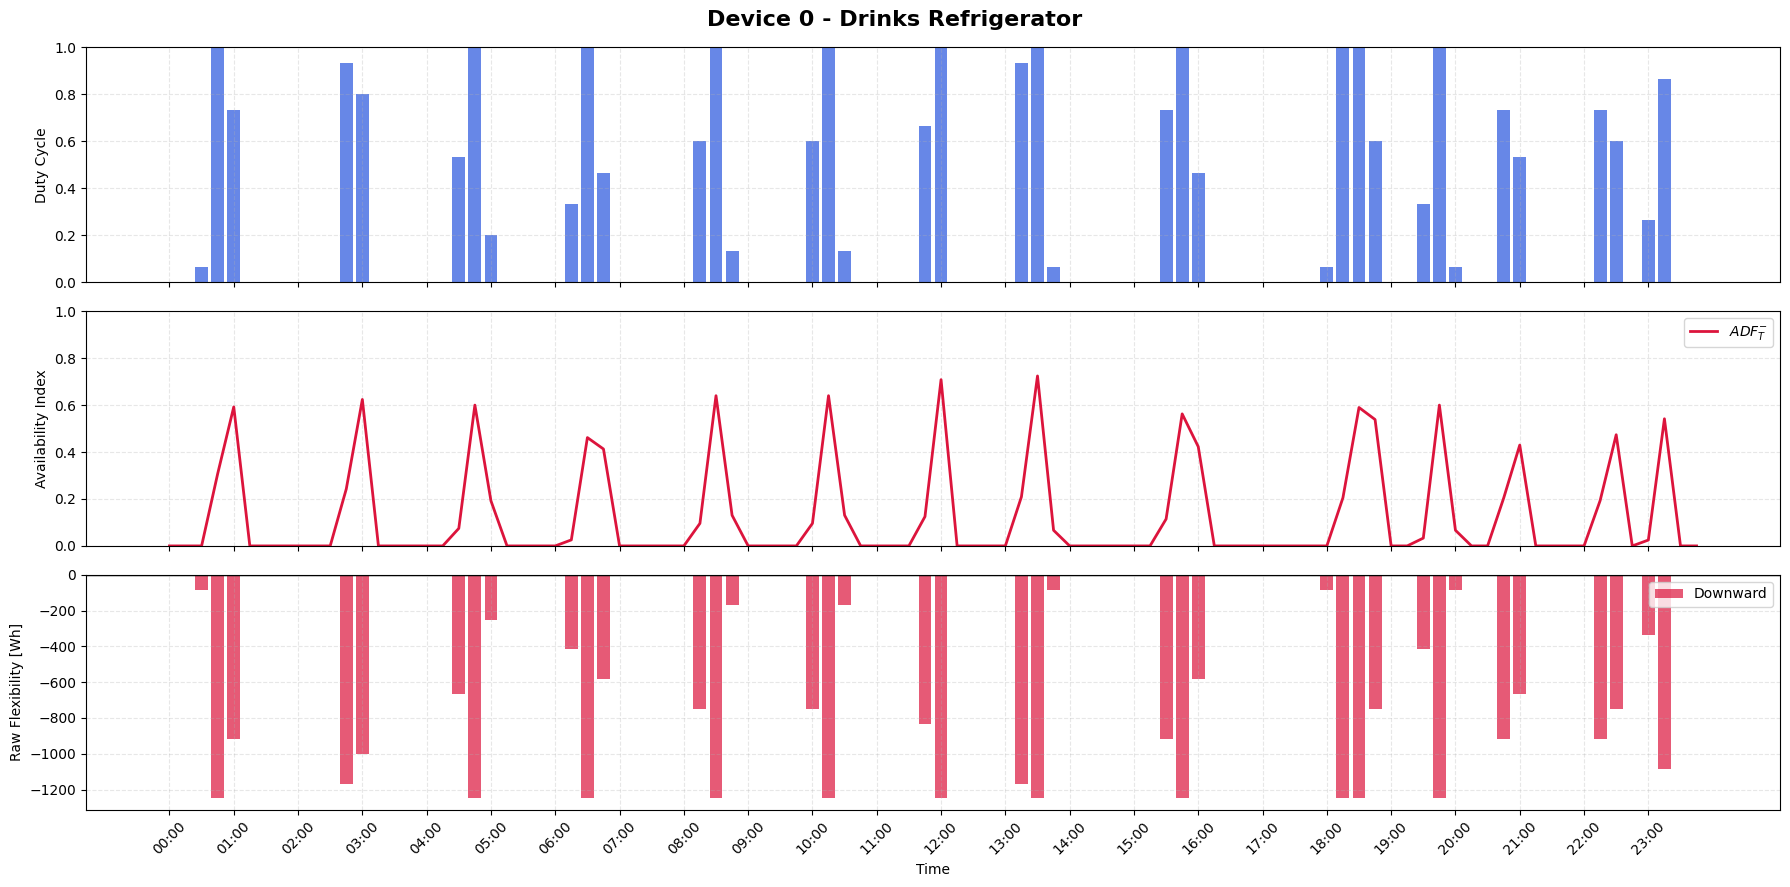

In [85]:
def plot_time_flex_device_summary(j, df=flexibility_15min_device):
    """
    Plots:
    1) Duty Cycle
    2) AI_T_up / AI_T_down
    3) RF_T_up_Wh / RF_T_down_Wh
    """

    dfj = df[df["appliance_j"] == j].copy()

    if dfj.empty:
        raise ValueError(f"No data found for appliance {j}")

    if dfj["Type"].iloc[0] != 2:
        print(f"Warning: appliance {j} is not time-flexible. Type={dfj['Type'].iloc[0]}")

    x = np.arange(len(dfj))
    labels = dfj["time"].astype(str).values

    fig, axes = plt.subplots(
        3, 1,
        figsize=(18, 9),
        sharex=True
    )

    title = f"Device {j}"
    if "appliance_name" in dfj.columns:
        title += f" - {dfj['appliance_name'].iloc[0]}"

    fig.suptitle(title, fontsize=16, fontweight="bold")

    # --------------------------------------------------
    # 1) Duty Cycle
    # --------------------------------------------------
    axes[0].bar(
        x,
        dfj["Duty_Cycle"],
        color="royalblue",
        alpha=0.8
    )

    axes[0].set_ylabel("Duty Cycle")
    axes[0].set_ylim(0, 1)
    axes[0].grid(True, linestyle="--", alpha=0.3)

    # --------------------------------------------------
    # 2) Availability Indices
    # --------------------------------------------------

    axes[1].plot(
        x,
        dfj["AI_T_down"],
        color="crimson",
        linewidth=2,
        label=r"$ADF_T^{-}$"
    )

    axes[1].set_ylabel("Availability Index")
    axes[1].set_ylim(0, 1)
    axes[1].legend(loc="upper right")
    axes[1].grid(True, linestyle="--", alpha=0.3)

    # --------------------------------------------------
    # 3) Raw Flexibility (Wh)
    # --------------------------------------------------
    axes[2].bar(
        x,
        -dfj["RF_T_down_Wh"],
        color="crimson",
        alpha=0.7,
        label="Downward"
    )

    axes[2].axhline(0, color="black", linewidth=1)

    axes[2].set_ylabel("Raw Flexibility [Wh]")
    axes[2].legend(loc="upper right")
    axes[2].grid(True, linestyle="--", alpha=0.3)

    # --------------------------------------------------
    # X axis
    # --------------------------------------------------
    step = 4

    axes[2].set_xticks(x[::step])
    axes[2].set_xticklabels(labels[::step], rotation=45)
    axes[2].set_xlabel("Time")

    plt.tight_layout()
    plt.show()

plot_time_flex_device_summary(0, df=flexibility_15min_device)

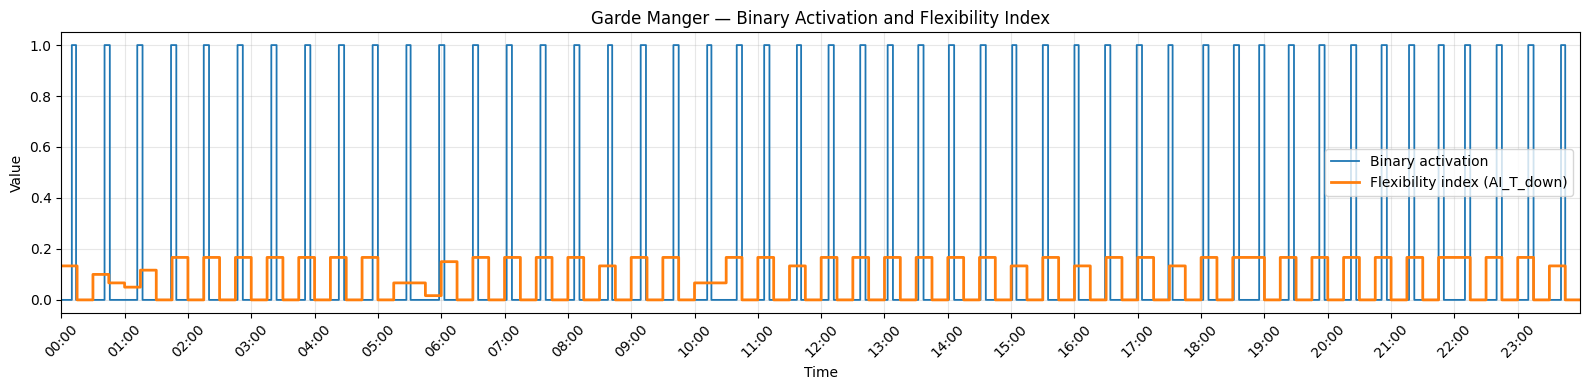

In [86]:
def plot_flexibility_vs_onoff(
    X_onoff_FC_matrix,
    flexibility_df,
    device_name,
    block_size=15,
    flexibility_col="AI_T_down"
):
    """
    Plots the minute-level binary activation together with the
    15-minute flexibility index for one device.
    """

    # Identify device column
    device_rows = (
        flexibility_df.loc[
            flexibility_df["appliance_name"] == device_name,
            ["appliance_j", "appliance_name"]
        ]
        .drop_duplicates()
    )

    if device_rows.empty:
        raise ValueError(
            f"Device '{device_name}' not found in flexibility_df."
        )

    device_j = int(device_rows["appliance_j"].iloc[0])

    # Validate matrix dimensions
    if X_onoff_FC_matrix.ndim != 2:
        raise ValueError("X_onoff_FC_matrix must be a 2D NumPy array.")

    if device_j >= X_onoff_FC_matrix.shape[1]:
        raise ValueError(
            f"Device index {device_j} exceeds matrix dimensions "
            f"{X_onoff_FC_matrix.shape}."
        )

    # Minute-level binary activation
    activation = X_onoff_FC_matrix[:, device_j].astype(float)

    # 15-minute flexibility index
    flex = (
        flexibility_df[
            flexibility_df["appliance_j"] == device_j
        ]
        .sort_values("block")
        .copy()
    )

    if flexibility_col not in flex.columns:
        raise ValueError(
            f"Column '{flexibility_col}' not found. "
            f"Available columns: {flex.columns.tolist()}"
        )

    # Expand each 15-minute value to minute resolution
    flexibility_minute = np.repeat(
        flex[flexibility_col].to_numpy(dtype=float),
        block_size
    )

    # Align both series
    n_minutes = min(
        len(activation),
        len(flexibility_minute)
    )

    activation = activation[:n_minutes]
    flexibility_minute = flexibility_minute[:n_minutes]

    minute_index = np.arange(n_minutes)

    # Hourly ticks
    tick_positions = np.arange(0, n_minutes, 60)
    tick_labels = [
        f"{minute // 60:02d}:00"
        for minute in tick_positions
    ]

    # Plot
    fig, ax = plt.subplots(figsize=(16, 4))

    ax.step(
        minute_index,
        activation,
        where="post",
        linewidth=1.3,
        label="Binary activation"
    )

    ax.step(
        minute_index,
        flexibility_minute,
        where="post",
        linewidth=2,
        label=f"Flexibility index ({flexibility_col})"
    )

    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(0, n_minutes - 1)

    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, rotation=45)

    ax.set_xlabel("Time")
    ax.set_ylabel("Value")
    ax.set_title(
        f"{device_name} — Binary Activation and Flexibility Index"
    )

    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
    
plot_flexibility_vs_onoff(
    X_onoff_FC_matrix=X_onoff_FC_matrix,
    flexibility_df=flexibility_15min_device,
    device_name="Garde Manger",
    block_size=BLOCK_SIZE,
    flexibility_col="AI_T_down"
)

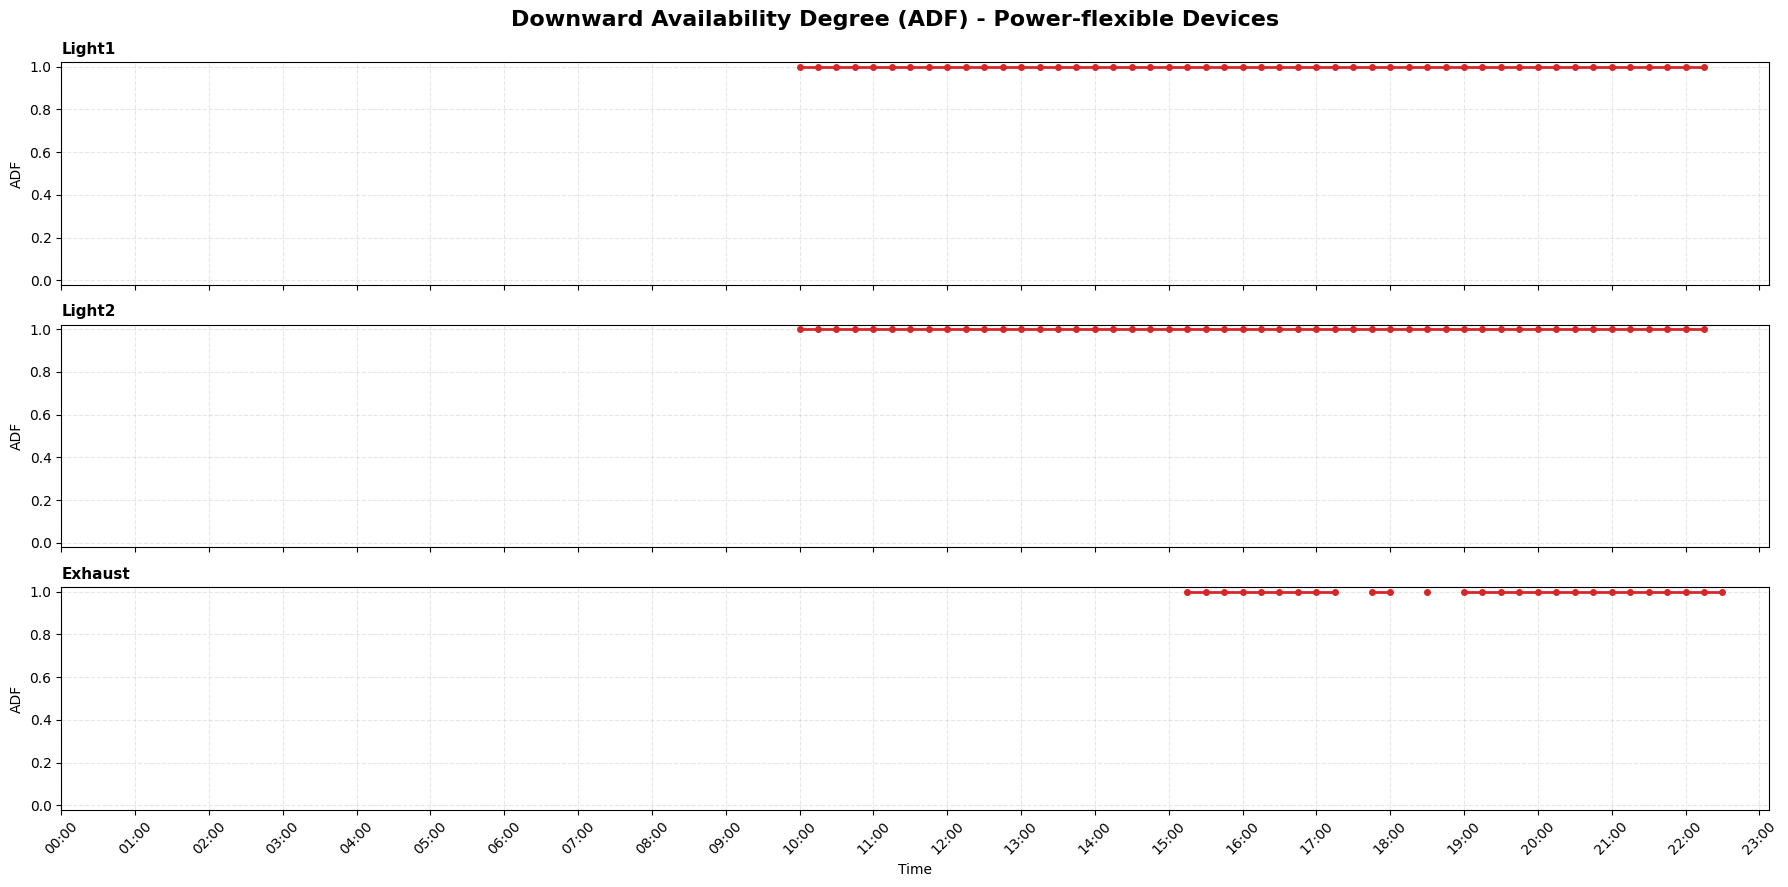

In [87]:

def plot_adf_p_lines(flexibility_15min_device):
    """
    One line plot per power-flexible device showing ADF_P_down over time.
    """

    df = flexibility_15min_device.copy()
    df = df[df["Type"] == 1].copy()

    if df.empty:
        print("No power-flexible devices found.")
        return

    devices = df["appliance_j"].unique()
    n = len(devices)

    fig, axes = plt.subplots(
        n,
        1,
        figsize=(18, max(3*n, 4)),
        sharex=True
    )

    if n == 1:
        axes = [axes]

    for ax, j in zip(axes, devices):

        dfj = (
            df[df["appliance_j"] == j]
            .sort_values("block")
        )

        x = np.arange(len(dfj))

        ax.plot(
            x,
            dfj["AI_P_down"],
            "-o",
            color="tab:red",
            linewidth=2,
            markersize=4
        )

        ax.set_ylim(-0.02, 1.02)
        ax.set_ylabel("ADF")

        ax.set_title(
            dfj["appliance_name"].iloc[0],
            loc="left",
            fontsize=11,
            fontweight="bold"
        )

        ax.grid(True, linestyle="--", alpha=0.3)

    labels = dfj["time"].astype(str).values
    step = max(1, len(labels)//24)

    axes[-1].set_xticks(x[::step])
    axes[-1].set_xticklabels(labels[::step], rotation=45)
    axes[-1].set_xlabel("Time")

    fig.suptitle(
        "Downward Availability Degree (ADF) - Power-flexible Devices",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()
plot_adf_p_lines(flexibility_15min_device)

# Caracterização BESS

In [88]:
def characterize_battery(
    blocks,
    capacity_kWh,
    soc_init_kWh,
    soc_min_kWh,
    soc_max_kWh,
    charge_power_max_kW,
    discharge_power_max_kW,
    eta_charge,
    eta_discharge,
    block_size_min=15
):
    """
    Creates the physical characterization of a battery for each
    optimization block.

    Parameters
    ----------
    blocks : iterable
        Optimization block identifiers.

    capacity_kWh : float
        Nominal or usable battery capacity [kWh].

    soc_init_kWh : float
        Initial stored energy at the beginning of the horizon [kWh].

    soc_min_kWh : float
        Minimum allowed stored energy [kWh].

    soc_max_kWh : float
        Maximum allowed stored energy [kWh].

    charge_power_max_kW : float
        Maximum battery charging power [kW].

    discharge_power_max_kW : float
        Maximum battery discharging power [kW].

    eta_charge : float
        Charging efficiency, between 0 and 1.

    eta_discharge : float
        Discharging efficiency, between 0 and 1.

    block_size_min : int or float
        Duration of each optimization block [minutes].

    Returns
    -------
    battery_characterization : pandas.DataFrame
        Battery physical parameters for each optimization block.

    battery_info : dict
        Global battery parameters.
    """

    # -------------------------
    # Input validation
    # -------------------------
    if capacity_kWh <= 0:
        raise ValueError("capacity_kWh must be greater than zero.")

    if not 0 <= soc_min_kWh <= soc_init_kWh <= soc_max_kWh:
        raise ValueError(
            "The SoC values must satisfy: "
            "soc_min_kWh <= soc_init_kWh <= soc_max_kWh."
        )

    if soc_max_kWh > capacity_kWh:
        raise ValueError(
            "soc_max_kWh cannot be greater than capacity_kWh."
        )

    if charge_power_max_kW < 0:
        raise ValueError(
            "charge_power_max_kW cannot be negative."
        )

    if discharge_power_max_kW < 0:
        raise ValueError(
            "discharge_power_max_kW cannot be negative."
        )

    if not 0 < eta_charge <= 1:
        raise ValueError(
            "eta_charge must be between 0 and 1."
        )

    if not 0 < eta_discharge <= 1:
        raise ValueError(
            "eta_discharge must be between 0 and 1."
        )

    if block_size_min <= 0:
        raise ValueError(
            "block_size_min must be greater than zero."
        )

    # -------------------------
    # Time conversion
    # -------------------------
    block_duration_h = block_size_min / 60.0

    # Maximum grid-side energy exchanged during one block
    charge_energy_max_kWh = (
        charge_power_max_kW
        * block_duration_h
    )

    discharge_energy_max_kWh = (
        discharge_power_max_kW
        * block_duration_h
    )

    # -------------------------
    # SoC percentages
    # -------------------------
    soc_init_pct = (
        100
        * soc_init_kWh
        / capacity_kWh
    )

    soc_min_pct = (
        100
        * soc_min_kWh
        / capacity_kWh
    )

    soc_max_pct = (
        100
        * soc_max_kWh
        / capacity_kWh
    )

    # -------------------------
    # Per-block characterization
    # -------------------------
    battery_characterization = pd.DataFrame({
        "block": list(blocks),
        "block_size_min": block_size_min,
        "block_duration_h": block_duration_h,
        "capacity_kWh": capacity_kWh,
        "soc_min_kWh": soc_min_kWh,
        "soc_max_kWh": soc_max_kWh,
        "charge_power_max_kW": charge_power_max_kW,
        "discharge_power_max_kW": discharge_power_max_kW,
        "charge_energy_max_kWh": charge_energy_max_kWh,
        "discharge_energy_max_kWh": discharge_energy_max_kWh,
        "eta_charge": eta_charge,
        "eta_discharge": eta_discharge
    })

    # -------------------------
    # Global information
    # -------------------------
    battery_info = {
        "capacity_kWh": capacity_kWh,
        "soc_init_kWh": soc_init_kWh,
        "soc_min_kWh": soc_min_kWh,
        "soc_max_kWh": soc_max_kWh,
        "soc_init_pct": soc_init_pct,
        "soc_min_pct": soc_min_pct,
        "soc_max_pct": soc_max_pct,
        "charge_power_max_kW": charge_power_max_kW,
        "discharge_power_max_kW": discharge_power_max_kW,
        "charge_energy_max_kWh": charge_energy_max_kWh,
        "discharge_energy_max_kWh": discharge_energy_max_kWh,
        "eta_charge": eta_charge,
        "eta_discharge": eta_discharge,
        "block_size_min": block_size_min,
        "block_duration_h": block_duration_h
    }

    return battery_characterization, battery_info

battery_characterization, battery_info = characterize_battery(
    blocks=range(N_BLOCKS),
    capacity_kWh=40.0,
    soc_init_kWh=20.0,
    soc_min_kWh=0.0,
    soc_max_kWh=40.0,
    charge_power_max_kW=10.0,
    discharge_power_max_kW=10.0,
    eta_charge=0.95,
    eta_discharge=0.95,
    block_size_min=BLOCK_SIZE
)

battery_characterization.head()

,block,block_size_min,block_duration_h,capacity_kWh,soc_min_kWh,soc_max_kWh,charge_power_max_kW,discharge_power_max_kW,charge_energy_max_kWh,discharge_energy_max_kWh,eta_charge,eta_discharge
0,0,15,0.25,40.0,0.0,40.0,10.0,10.0,2.5,2.5,0.95,0.95
1,1,15,0.25,40.0,0.0,40.0,10.0,10.0,2.5,2.5,0.95,0.95
2,2,15,0.25,40.0,0.0,40.0,10.0,10.0,2.5,2.5,0.95,0.95
3,3,15,0.25,40.0,0.0,40.0,10.0,10.0,2.5,2.5,0.95,0.95
4,4,15,0.25,40.0,0.0,40.0,10.0,10.0,2.5,2.5,0.95,0.95


# Caracterização PV

In [ ]:
import numpy as np
import pandas as pd


def characterize_pv_numpy(
    pv_forecast_kW,
    day_start="2026-01-01 00:00",
    block_size_min=15,
    installed_power_kWp=None,
    inverter_power_max_kW=None
):
    """
    Characterizes a minute-level PV forecast provided as a NumPy array.

    Parameters
    ----------
    pv_forecast_kW : numpy.ndarray
        Minute-resolution PV forecast [kW].
        For one complete day, it should contain 1440 values.

    day_start : str or pandas.Timestamp
        Timestamp corresponding to the first value of the forecast.

    block_size_min : int
        Optimization block duration [minutes].

    installed_power_kWp : float, optional
        Installed PV capacity [kWp].

    inverter_power_max_kW : float, optional
        Maximum inverter output power [kW].

    Returns
    -------
    pv_characterization : pandas.DataFrame
        One row per optimization block.

    pv_info : dict
        Global PV parameters.
    """

    # Convert input to a 1D NumPy array
    pv_forecast_kW = np.asarray(
        pv_forecast_kW,
        dtype=float
    ).reshape(-1)

    if len(pv_forecast_kW) == 0:
        raise ValueError("pv_forecast_kW cannot be empty.")

    if block_size_min <= 0:
        raise ValueError("block_size_min must be greater than zero.")

    # Replace invalid values and prevent negative PV generation
    pv_forecast_raw_kW = np.nan_to_num(
        pv_forecast_kW,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    pv_forecast_raw_kW = np.clip(
        pv_forecast_raw_kW,
        a_min=0.0,
        a_max=None
    )

    # -------------------------
    # Physical power limit
    # -------------------------
    power_limits = []

    if installed_power_kWp is not None:
        power_limits.append(float(installed_power_kWp))

    if inverter_power_max_kW is not None:
        power_limits.append(float(inverter_power_max_kW))

    if power_limits:
        effective_power_limit_kW = min(power_limits)

        pv_available_kW = np.minimum(
            pv_forecast_raw_kW,
            effective_power_limit_kW
        )
    else:
        effective_power_limit_kW = None
        pv_available_kW = pv_forecast_raw_kW.copy()

    # -------------------------
    # Timestamp vector
    # -------------------------
    timestamps = pd.date_range(
        start=pd.Timestamp(day_start),
        periods=len(pv_forecast_raw_kW),
        freq="min"
    )

    # -------------------------
    # Block assignment
    # -------------------------
    block = np.arange(len(pv_forecast_raw_kW)) // block_size_min

    minute_data = pd.DataFrame({
        "timestamp": timestamps,
        "block": block,
        "PV_forecast_raw_kW": pv_forecast_raw_kW,
        "PV_available_kW": pv_available_kW
    })

    minute_data["PV_forecast_kWh_min"] = (
        minute_data["PV_forecast_raw_kW"] / 60.0
    )

    minute_data["PV_available_kWh_min"] = (
        minute_data["PV_available_kW"] / 60.0
    )

    # -------------------------
    # Aggregate blocks
    # -------------------------
    pv_characterization = (
        minute_data
        .groupby("block", as_index=False)
        .agg(
            block_start=("timestamp", "first"),

            PV_forecast_kW_mean=(
                "PV_forecast_raw_kW",
                "mean"
            ),

            PV_available_kW_mean=(
                "PV_available_kW",
                "mean"
            ),

            PV_forecast_kWh=(
                "PV_forecast_kWh_min",
                "sum"
            ),

            PV_available_kWh=(
                "PV_available_kWh_min",
                "sum"
            ),

            observed_minutes=(
                "timestamp",
                "count"
            )
        )
    )

    pv_characterization["PV_clipped_kWh"] = (
        pv_characterization["PV_forecast_kWh"]
        - pv_characterization["PV_available_kWh"]
    )

    pv_characterization["complete_block"] = (
        pv_characterization["observed_minutes"]
        == block_size_min
    )

    pv_characterization = pv_characterization[
        [
            "block",
            "block_start",
            "PV_forecast_kW_mean",
            "PV_available_kW_mean",
            "PV_forecast_kWh",
            "PV_available_kWh",
            "PV_clipped_kWh",
            "complete_block"
        ]
    ]

    # -------------------------
    # Global information
    # -------------------------
    pv_info = {
        "installed_power_kWp": installed_power_kWp,
        "inverter_power_max_kW": inverter_power_max_kW,
        "effective_power_limit_kW": effective_power_limit_kW,
        "block_size_min": block_size_min,
        "number_of_minutes": len(pv_forecast_raw_kW),
        "number_of_blocks": len(pv_characterization)
    }

    return pv_characterization, pv_info

pv_characterization, pv_info = characterize_pv_numpy(
    pv_forecast_kW=pv_forecast_kW,
    day_start=day_start,
    block_size_min=15,
    installed_power_kWp=installed_power_kWp_pv,
    inverter_power_max_kW=inverter_power_max_kW_pv
)
display(
    pv_characterization[
        pv_characterization["PV_available_kW_mean"] > 0
    ]
)

,block,block_start,PV_forecast_kW_mean,PV_available_kW_mean,PV_forecast_kWh,PV_available_kWh,PV_clipped_kWh,complete_block
40,40,2026-07-17 10:00:00,10.0,10.0,2.5,2.5,0.0,True
41,41,2026-07-17 10:15:00,10.0,10.0,2.5,2.5,0.0,True
42,42,2026-07-17 10:30:00,10.0,10.0,2.5,2.5,0.0,True
43,43,2026-07-17 10:45:00,10.0,10.0,2.5,2.5,0.0,True
44,44,2026-07-17 11:00:00,10.0,10.0,2.5,2.5,0.0,True
45,45,2026-07-17 11:15:00,10.0,10.0,2.5,2.5,0.0,True
46,46,2026-07-17 11:30:00,10.0,10.0,2.5,2.5,0.0,True
47,47,2026-07-17 11:45:00,10.0,10.0,2.5,2.5,0.0,True
48,48,2026-07-17 12:00:00,10.0,10.0,2.5,2.5,0.0,True
49,49,2026-07-17 12:15:00,10.0,10.0,2.5,2.5,0.0,True


# Planeamento Flex - Devices Only

In [106]:
timezone_energy_limits_Wh = {
    0: 1250.0,
    1: 3750.0,
    2: 6250.0,
    3: 2500.0
}

def get_time_zone_from_block(k, block_size=BLOCK_SIZE):
    minute = int(k) * block_size

    if minute < 600:
        return 0
    elif minute < 1170:
        return 1
    elif minute < 1350:
        return 2
    else:
        return 3


def get_e_lim_k(k, block_size=BLOCK_SIZE):
    tz = get_time_zone_from_block(k, block_size)
    return timezone_energy_limits_Wh[tz]


def get_p_lim_k(k, block_size=BLOCK_SIZE):
    return get_e_lim_k(k, block_size) * 60 / block_size


P_lim = np.array([
    get_p_lim_k(k, BLOCK_SIZE)
    for k in range(N_BLOCKS)
])

E_lim = np.array([
    get_e_lim_k(k, BLOCK_SIZE)
    for k in range(N_BLOCKS)
])

def add_energy_columns(df, E_lim, block_size=15):
    df = df.copy()

    df["DC_base"] = df["Duty_Cycle"].fillna(0.0)
    df["Y_base"] = df["Y_base"].fillna(0.0)

    if "DC_rec" not in df.columns:
        df["DC_rec"] = df["DC_base"]

    if "Y_rec" not in df.columns:
        df["Y_rec"] = df["Y_base"]

    df["E_base_row_Wh"] = 0.0
    df["E_rec_row_Wh"] = 0.0

    mask_t = df["Type"] == 2
    mask_p = df["Type"] == 1
    mask_nf = df["Type"] == 0

    df.loc[mask_t, "E_base_row_Wh"] = (
        df.loc[mask_t, "Power_max_W"] *
        df.loc[mask_t, "DC_base"] *
        block_size / 60
    )

    df.loc[mask_t, "E_rec_row_Wh"] = (
        df.loc[mask_t, "Power_max_W"] *
        df.loc[mask_t, "DC_rec"] *
        block_size / 60
    )

    df.loc[mask_p, "E_base_row_Wh"] = (
        df.loc[mask_p, "Power_max_W"] *
        df.loc[mask_p, "Y_base"] *
        block_size / 60
    )

    df.loc[mask_p, "E_rec_row_Wh"] = (
        df.loc[mask_p, "Power_max_W"] *
        df.loc[mask_p, "Y_rec"] *
        block_size / 60
    )

    df.loc[mask_nf, "E_base_row_Wh"] = (
        df.loc[mask_nf, "Power_max_W"] *
        df.loc[mask_nf, "Duty_Cycle"].fillna(0.0) *
        block_size / 60
    )

    df.loc[mask_nf, "E_rec_row_Wh"] = df.loc[mask_nf, "E_base_row_Wh"]

    return df

def build_schedule_summary(df, E_lim, block_size=15, E_rlx_dict=None):
    df = add_energy_columns(df, E_lim, block_size)

    summary = (
        df.groupby(["block", "time"], as_index=False)
        .agg(
            E_base_Wh=("E_base_row_Wh", "sum"),
            E_rec_Wh=("E_rec_row_Wh", "sum")
        )
    )

    summary["E_lim_Wh"] = summary["block"].apply(
        lambda k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
    )

    summary["initial_violation_Wh"] = (
        summary["E_base_Wh"] - summary["E_lim_Wh"]
    ).clip(lower=0)

    summary["remaining_violation_Wh"] = (
        summary["E_rec_Wh"] - summary["E_lim_Wh"]
    ).clip(lower=0)

    summary["reduction_Wh"] = summary["E_base_Wh"] - summary["E_rec_Wh"]

    summary["P_base_W_equiv"] = summary["E_base_Wh"] * 60 / block_size
    summary["P_rec_W_equiv"] = summary["E_rec_Wh"] * 60 / block_size
    summary["P_lim_W_equiv"] = summary["E_lim_Wh"] * 60 / block_size

    if E_rlx_dict is not None:
        summary["E_rlx_Wh"] = summary["block"].map(E_rlx_dict)
    else:
        summary["E_rlx_Wh"] = np.nan

    return summary

print("Energy Limits (Wh) per block:")
for k, lim in enumerate(E_lim):
    print(f"  Block {k}: {lim}")
    

Energy Limits (Wh) per block:
  Block 0: 1250.0
  Block 1: 1250.0
  Block 2: 1250.0
  Block 3: 1250.0
  Block 4: 1250.0
  Block 5: 1250.0
  Block 6: 1250.0
  Block 7: 1250.0
  Block 8: 1250.0
  Block 9: 1250.0
  Block 10: 1250.0
  Block 11: 1250.0
  Block 12: 1250.0
  Block 13: 1250.0
  Block 14: 1250.0
  Block 15: 1250.0
  Block 16: 1250.0
  Block 17: 1250.0
  Block 18: 1250.0
  Block 19: 1250.0
  Block 20: 1250.0
  Block 21: 1250.0
  Block 22: 1250.0
  Block 23: 1250.0
  Block 24: 1250.0
  Block 25: 1250.0
  Block 26: 1250.0
  Block 27: 1250.0
  Block 28: 1250.0
  Block 29: 1250.0
  Block 30: 1250.0
  Block 31: 1250.0
  Block 32: 1250.0
  Block 33: 1250.0
  Block 34: 1250.0
  Block 35: 1250.0
  Block 36: 1250.0
  Block 37: 1250.0
  Block 38: 1250.0
  Block 39: 1250.0
  Block 40: 3750.0
  Block 41: 3750.0
  Block 42: 3750.0
  Block 43: 3750.0
  Block 44: 3750.0
  Block 45: 3750.0
  Block 46: 3750.0
  Block 47: 3750.0
  Block 48: 3750.0
  Block 49: 3750.0
  Block 50: 3750.0
  Block 51:

### Baseline

In [111]:
# =========================
# BASELINE SUMMARY
# =========================

baseline_df = flexibility_15min_device.copy()

baseline_df["DC_base"] = baseline_df["Duty_Cycle"].fillna(0.0)

baseline_df["n_on_base"] = np.where(
    baseline_df["Type"] == 2,
    np.rint(
        baseline_df["DC_base"] * BLOCK_SIZE
    ).astype(int),
    np.nan
)

baseline_df["Y_base"] = baseline_df["Y_base"].fillna(0.0)

baseline_df["E_base_row_Wh"] = 0.0

mask_t = baseline_df["Type"] == 2
mask_p = baseline_df["Type"] == 1
mask_nf = baseline_df["Type"] == 0

# Time-flexible devices
baseline_df.loc[mask_t, "E_base_row_Wh"] = (
    baseline_df.loc[mask_t, "Power_max_W"]
    * baseline_df.loc[mask_t, "n_on_base"]
    / 60
)

# Power-flexible devices
baseline_df.loc[mask_p, "E_base_row_Wh"] = (
    baseline_df.loc[mask_p, "Power_max_W"]
    * baseline_df.loc[mask_p, "Y_base"]
    * BLOCK_SIZE / 60
)

# Non-flexible devices
baseline_df.loc[mask_nf, "E_base_row_Wh"] = (
    baseline_df.loc[mask_nf, "Power_max_W"]
    * baseline_df.loc[mask_nf, "Duty_Cycle"].fillna(0.0)
    * BLOCK_SIZE / 60
)

baseline_summary = (
    baseline_df
    .groupby(["block", "time"], as_index=False)
    .agg(
        E_base_Wh=("E_base_row_Wh", "sum")
    )
)

baseline_summary["E_rec_Wh"] = baseline_summary["E_base_Wh"]

baseline_summary["E_lim_Wh"] = baseline_summary["block"].apply(
    lambda k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
)

baseline_summary["initial_violation_Wh"] = (
    baseline_summary["E_base_Wh"]
    - baseline_summary["E_lim_Wh"]
).clip(lower=0)

baseline_summary["remaining_violation_Wh"] = (
    baseline_summary["E_rec_Wh"]
    - baseline_summary["E_lim_Wh"]
).clip(lower=0)

baseline_summary["reduction_Wh"] = 0.0
baseline_summary["E_rlx_Wh"] = np.nan


### Greedy Algorithm

In [131]:
def greedy_algorithm(
    flexibility_15min_device,
    E_lim,
    block_size=15,
    y_step=0.10,
    ai_p_threshold=0.0,
    ai_t_threshold=0.0
):
    df = flexibility_15min_device.copy()

    # -------------------------
    # Base variables
    # -------------------------
    df["DC_base"] = df["Duty_Cycle"].fillna(0.0)

    df["n_on_base"] = np.where(
        df["Type"] == 2,
        np.rint(df["DC_base"] * block_size).astype(int),
        np.nan
    )

    df["n_on_rec"] = df["n_on_base"].copy()

    df["DC_rec"] = np.where(
        df["Type"] == 2,
        df["n_on_rec"] / block_size,
        df["DC_base"]
    )

    df["n_on_reduction"] = 0.0
    df["DC_reduction"] = 0.0

    df["Y_base"] = df["Y_base"].fillna(0.0)
    df["Y_rec"] = df["Y_base"].copy()
    df["Y_reduction"] = 0.0

    # -------------------------
    # Energy computation
    # -------------------------
    def update_energy_columns(df):
        df = df.copy()

        df["E_base_row_Wh"] = 0.0
        df["E_rec_row_Wh"] = 0.0

        mask_t = df["Type"] == 2
        mask_p = df["Type"] == 1
        mask_nf = df["Type"] == 0

        df.loc[mask_t, "E_base_row_Wh"] = (
            df.loc[mask_t, "Power_max_W"] *
            df.loc[mask_t, "n_on_base"] / 60
        )

        df.loc[mask_t, "E_rec_row_Wh"] = (
            df.loc[mask_t, "Power_max_W"] *
            df.loc[mask_t, "n_on_rec"] / 60
        )

        df.loc[mask_p, "E_base_row_Wh"] = (
            df.loc[mask_p, "Power_max_W"] *
            df.loc[mask_p, "Y_base"] *
            block_size / 60
        )

        df.loc[mask_p, "E_rec_row_Wh"] = (
            df.loc[mask_p, "Power_max_W"] *
            df.loc[mask_p, "Y_rec"] *
            block_size / 60
        )

        df.loc[mask_nf, "E_base_row_Wh"] = (
            df.loc[mask_nf, "Power_max_W"] *
            df.loc[mask_nf, "Duty_Cycle"].fillna(0.0) *
            block_size / 60
        )

        df.loc[mask_nf, "E_rec_row_Wh"] = df.loc[mask_nf, "E_base_row_Wh"]

        return df

    # -------------------------
    # Greedy loop
    # -------------------------
    for k in sorted(df["block"].unique()):

        E_lim_k_Wh = E_lim[k] if hasattr(E_lim, "__len__") else E_lim
        block_mask = df["block"] == k

        df = update_energy_columns(df)
        E_rec_Wh = df.loc[block_mask, "E_rec_row_Wh"].sum()

        # =========================
        # 1) POWER-FLEXIBLE FIRST
        # =========================
        if E_rec_Wh > E_lim_k_Wh:

            candidates_p = df[
                block_mask &
                (df["Type"] == 1) &
                (df["AI_P_down"] >= ai_p_threshold) &
                (df["RF_P_down_Wh"] > 0)
            ].sort_values(
                by="AI_P_down",
                ascending=False
            )

            for idx, row in candidates_p.iterrows():

                while E_rec_Wh > E_lim_k_Wh + 1e-6:

                    j = int(row["appliance_j"])
                    current_y = df.loc[idx, "Y_rec"]

                    if current_y <= Y_min[j] + 1e-9:
                        break

                    new_y = max(Y_min[j], current_y - y_step)
                    delta_y = current_y - new_y

                    df.loc[idx, "Y_rec"] = new_y
                    df.loc[idx, "Y_reduction"] += delta_y

                    df = update_energy_columns(df)
                    E_rec_Wh = df.loc[block_mask, "E_rec_row_Wh"].sum()

        # =========================
        # 2) TIME-FLEXIBLE SECOND
        # =========================
        if E_rec_Wh > E_lim_k_Wh:

            candidates_t = df[
                block_mask &
                (df["Type"] == 2) &
                (df["AI_T_down"] >= ai_t_threshold) &
                (df["RF_T_down_Wh"] > 0) &
                (df["n_on_rec"] > 0)
            ].sort_values(
                by="AI_T_down",
                ascending=False
            )

            for idx, row in candidates_t.iterrows():

                while E_rec_Wh > E_lim_k_Wh + 1e-6:

                    current_n = df.loc[idx, "n_on_rec"]

                    if current_n <= 0:
                        break

                    new_n = max(0, current_n - 1)
                    delta_n = current_n - new_n

                    df.loc[idx, "n_on_rec"] = new_n
                    df.loc[idx, "n_on_reduction"] += delta_n

                    df.loc[idx, "DC_rec"] = new_n / block_size
                    df.loc[idx, "DC_reduction"] = (
                        df.loc[idx, "DC_base"] - df.loc[idx, "DC_rec"]
                    )

                    df = update_energy_columns(df)
                    E_rec_Wh = df.loc[block_mask, "E_rec_row_Wh"].sum()

    # -------------------------
    # Final update
    # -------------------------
    df = update_energy_columns(df)

    df["DC_change"] = df["DC_rec"] - df["DC_base"]
    df["Y_change"] = df["Y_rec"] - df["Y_base"]

    # -------------------------
    # Summary
    # -------------------------
    summary = (
        df.groupby(["block", "time"], as_index=False)
        .agg(
            E_base_Wh=("E_base_row_Wh", "sum"),
            E_rec_Wh=("E_rec_row_Wh", "sum")
        )
    )

    summary["E_lim_Wh"] = summary["block"].apply(
        lambda k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
    )

    summary["initial_violation_Wh"] = (
        summary["E_base_Wh"] - summary["E_lim_Wh"]
    ).clip(lower=0)

    summary["remaining_violation_Wh"] = (
        summary["E_rec_Wh"] - summary["E_lim_Wh"]
    ).clip(lower=0)

    summary["reduction_Wh"] = summary["E_base_Wh"] - summary["E_rec_Wh"]

    summary["E_rlx_Wh"] = np.nan

    return df, summary
schedule_15min_device, greedy_summary = greedy_algorithm(
    flexibility_15min_device=flexibility_15min_device,
    E_lim=E_lim,
    block_size=BLOCK_SIZE,
    y_step=0.10,
    ai_p_threshold=0.0,
    ai_t_threshold=0.0
)

### Optimization Algorithm

### Optimização com horizonte por Timezone 

In [116]:
import pyomo.environ as pe
import numpy as np
import pandas as pd


def optimization_algorithm(
    flexibility_15min_device,
    E_lim,
    Y_min,
    Y_max,
    block_size=15,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="glpk",
    epsilon_P = 0.1
):
    df = flexibility_15min_device.copy()

    # -------------------------
    # Sets
    # -------------------------
    blocks = sorted(df["block"].unique())
    J_T = sorted(df.loc[df["Type"] == 2, "appliance_j"].unique())
    J_P = sorted(df.loc[df["Type"] == 1, "appliance_j"].unique())
    J_NF = sorted(df.loc[df["Type"] == 0, "appliance_j"].unique())

    # -------------------------
    # Helper function
    # -------------------------
    def get_val(j, k, col, default=0.0):
        s = df.loc[
            (df["appliance_j"] == j) &
            (df["block"] == k),
            col
        ]

        if s.empty or pd.isna(s.iloc[0]):
            return default

        return float(s.iloc[0])

    # -------------------------
    # Parameters
    # -------------------------
    Pmax = {
        j: float(df.loc[df["appliance_j"] == j, "Power_max_W"].iloc[0])
        for j in df["appliance_j"].unique()
    }

    DC_base = {
        (j, k): get_val(j, k, "Duty_Cycle", 0.0)
        for j in J_T for k in blocks
    }

    n_base = {
        (j, k): int(round(DC_base[j, k] * block_size))
        for j in J_T for k in blocks
    }

    Y_base = {
        (j, k): get_val(j, k, "Y_base", 0.0)
        for j in J_P for k in blocks
    }

    ADF_T = {
        (j, k): get_val(j, k, "AI_T_down", 0.0)
        for j in J_T for k in blocks
    }

    ADF_P = {
        (j, k): get_val(j, k, "AI_P_down", 0.0)
        for j in J_P for k in blocks
    }

    E_NF = {}
    for k in blocks:
        e = 0.0
        for j in J_NF:
            dc_nf = get_val(j, k, "Duty_Cycle", 0.0)
            e += Pmax[j] * dc_nf * block_size / 60
        E_NF[k] = e

    E_lim_dict = {
        k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
        for k in blocks
    }

    # -------------------------
    # Model
    # -------------------------
    m = pe.ConcreteModel()

    m.K = pe.Set(initialize=blocks)
    m.JT = pe.Set(initialize=J_T)
    m.JP = pe.Set(initialize=J_P)

    # -------------------------
    # Decision variables
    # -------------------------
    # Number of ON minutes in each block
    m.n_on = pe.Var(
        m.JT,
        m.K,
        domain=pe.NonNegativeIntegers,
        bounds=(0, block_size)
    )

    # Power fraction for power-flexible devices
    m.Y_rec = pe.Var(
        m.JP,
        m.K,
        bounds=(0, 1)
    )

    # Energy relaxation
    m.E_rlx = pe.Var(
        m.K,
        bounds=(0, None)
    )

    # Absolute deviation variables
    m.dN = pe.Var(
        m.JT,
        m.K,
        bounds=(0, None)
    )

    m.dY = pe.Var(
        m.JP,
        m.K,
        bounds=(0, None)
    )

    # -------------------------
    # Energy limit constraint
    # -------------------------
    def energy_limit_rule(m, k):

        E_time = sum(
            Pmax[j] * m.n_on[j, k] / 60
            for j in m.JT
        )

        E_power = sum(
            Pmax[j] * m.Y_rec[j, k] * block_size / 60
            for j in m.JP
        )

        return E_time + E_power + E_NF[k] <= E_lim_dict[k] + m.E_rlx[k]

    m.energy_limit = pe.Constraint(
        m.K,
        rule=energy_limit_rule
    )
    
    # -------------------------
    # Time-zone compensation constraints
    # -------------------------

    time_zones = sorted(set(
        get_time_zone_from_block(k, block_size)
        for k in blocks
    ))

    for j in J_T:

        for z in time_zones:

            zone_blocks = [
                k for k in blocks
                if get_time_zone_from_block(k, block_size) == z
            ]

            if len(zone_blocks) == 0:
                continue

            cname = f"timezone_conservation_j{j}_z{z}"

            m.add_component(
                cname,
                pe.Constraint(
                    expr=sum(m.n_on[j, k] for k in zone_blocks)
                    ==
                    sum(n_base[j, k] for k in zone_blocks)
                )
            )

    # -------------------------
    # Power-flexible bounds
    # -------------------------
    def y_min_rule(m, j, k):
        if Y_base[j, k] <= 1e-9:
            return m.Y_rec[j, k] == 0
        return m.Y_rec[j, k] >= Y_min[j]

    def y_max_rule(m, j, k):
        if Y_base[j, k] <= 1e-9:
            return pe.Constraint.Skip
        return m.Y_rec[j, k] <= Y_max[j]

    m.y_min_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_min_rule
    )

    m.y_max_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_max_rule
    )

    # -------------------------
    # Absolute value linearization for n_on
    # -------------------------
    def dN_pos_rule(m, j, k):
        return m.dN[j, k] >= m.n_on[j, k] - n_base[j, k]

    def dN_neg_rule(m, j, k):
        return m.dN[j, k] >= n_base[j, k] - m.n_on[j, k]

    m.dN_pos = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_pos_rule
    )

    m.dN_neg = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_neg_rule
    )

    # -------------------------
    # Absolute value linearization for Y
    # -------------------------
    def dY_pos_rule(m, j, k):
        return m.dY[j, k] >= m.Y_rec[j, k] - Y_base[j, k]

    def dY_neg_rule(m, j, k):
        return m.dY[j, k] >= Y_base[j, k] - m.Y_rec[j, k]

    m.dY_pos = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_pos_rule
    )

    m.dY_neg = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_neg_rule
    )

    # -------------------------
    # Objective function
    # -------------------------
    m.obj = pe.Objective(
        expr=
        lambda_slack * sum(
            m.E_rlx[k]
            for k in m.K
        )
        +
        lambda_T * sum(
            (1 - ADF_T[j, k]) * m.dN[j, k]
            for j in m.JT for k in m.K
        )
        +
        lambda_P * sum(
            (epsilon_P + (1 - ADF_P[j, k])) * m.dY[j, k]
            for j in m.JP for k in m.K
        ),
        sense=pe.minimize
    )

    # -------------------------
    # Solve
    # -------------------------
    solver = pe.SolverFactory(solver_name)
    result = solver.solve(m, tee=False)

    # -------------------------
    # Extract outputs
    # -------------------------
    out = df.copy()

    out["DC_base"] = out["Duty_Cycle"].fillna(0.0)
    out["Y_base"] = out["Y_base"].fillna(0.0)

    out["n_on_base"] = np.nan
    out["n_on_rec"] = np.nan

    out["DC_rec"] = out["DC_base"]
    out["Y_rec"] = out["Y_base"]

    for j in J_T:
        for k in blocks:
            mask = (out["appliance_j"] == j) & (out["block"] == k)

            n_rec = pe.value(m.n_on[j, k])

            out.loc[mask, "n_on_base"] = n_base[j, k]
            out.loc[mask, "n_on_rec"] = n_rec
            out.loc[mask, "DC_rec"] = n_rec / block_size

    for j in J_P:
        for k in blocks:
            mask = (out["appliance_j"] == j) & (out["block"] == k)

            out.loc[mask, "Y_rec"] = pe.value(m.Y_rec[j, k])

    out["DC_change"] = out["DC_rec"] - out["DC_base"]
    out["Y_change"] = out["Y_rec"] - out["Y_base"]

    if "add_energy_columns" in globals():
        out = add_energy_columns(out, E_lim, block_size)

    E_rlx_dict = {
        k: pe.value(m.E_rlx[k])
        for k in blocks
    }

    summary = build_schedule_summary(
            out,
            E_lim,
            block_size,
            E_rlx_dict=E_rlx_dict)



    return out, summary, m, result

optimization_timezone_horizon_15min_device, optimization_timezone_horizon, model2, result2 = optimization_algorithm(
    flexibility_15min_device=flexibility_15min_device,
    E_lim=E_lim, 
    Y_min=Y_min,
    Y_max=Y_max,
    block_size=BLOCK_SIZE,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="highs",
    epsilon_P=0.1
    )

### Optimization with compensation (Different for buffered/operational)

In [118]:
def optimization_algorithm(
    flexibility_15min_device,
    E_lim,
    Y_min,
    Y_max,
    block_size=15,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="glpk",
    epsilon_P = 0.1
):
    df = flexibility_15min_device.copy()

    # -------------------------
    # Sets
    # -------------------------
    blocks = sorted(df["block"].unique())
    J_T = sorted(df.loc[df["Type"] == 2, "appliance_j"].unique())
    J_P = sorted(df.loc[df["Type"] == 1, "appliance_j"].unique())
    J_NF = sorted(df.loc[df["Type"] == 0, "appliance_j"].unique())

    # -------------------------
    # Helper function
    # -------------------------
    def get_val(j, k, col, default=0.0):
        s = df.loc[
            (df["appliance_j"] == j) &
            (df["block"] == k),
            col
        ]

        if s.empty or pd.isna(s.iloc[0]):
            return default

        return float(s.iloc[0])

    # -------------------------
    # Parameters
    # -------------------------
    Pmax = {
        j: float(df.loc[df["appliance_j"] == j, "Power_max_W"].iloc[0])
        for j in df["appliance_j"].unique()
    }

    DC_base = {
        (j, k): get_val(j, k, "Duty_Cycle", 0.0)
        for j in J_T for k in blocks
    }

    n_base = {
        (j, k): int(round(DC_base[j, k] * block_size))
        for j in J_T for k in blocks
    }

    Y_base = {
        (j, k): get_val(j, k, "Y_base", 0.0)
        for j in J_P for k in blocks
    }

    ADF_T = {
        (j, k): get_val(j, k, "AI_T_down", 0.0)
        for j in J_T for k in blocks
    }

    ADF_P = {
        (j, k): get_val(j, k, "AI_P_down", 0.0)
        for j in J_P for k in blocks
    }

    E_NF = {}
    for k in blocks:
        e = 0.0
        for j in J_NF:
            dc_nf = get_val(j, k, "Duty_Cycle", 0.0)
            e += Pmax[j] * dc_nf * block_size / 60
        E_NF[k] = e

    E_lim_dict = {
        k: E_lim[k] if hasattr(E_lim, "__len__") else E_lim
        for k in blocks
    }

    # -------------------------
    # Model
    # -------------------------
    m = pe.ConcreteModel()

    m.K = pe.Set(initialize=blocks)
    m.JT = pe.Set(initialize=J_T)
    m.JP = pe.Set(initialize=J_P)

    # -------------------------
    # Decision variables
    # -------------------------
    # Number of ON minutes in each block
    m.n_on = pe.Var(
        m.JT,
        m.K,
        domain=pe.NonNegativeIntegers,
        bounds=(0, block_size)
    )

    # Power fraction for power-flexible devices
    m.Y_rec = pe.Var(
        m.JP,
        m.K,
        bounds=(0, 1)
    )

    # Energy relaxation
    m.E_rlx = pe.Var(
        m.K,
        bounds=(0, None)
    )

    # Absolute deviation variables
    m.dN = pe.Var(
        m.JT,
        m.K,
        bounds=(0, None)
    )

    m.dY = pe.Var(
        m.JP,
        m.K,
        bounds=(0, None)
    )

    # -------------------------
    # Energy balance constraint
    # -------------------------
    def energy_limit_rule(m, k):

        E_time = sum(
            Pmax[j] * m.n_on[j, k] / 60
            for j in m.JT
        )

        E_power = sum(
            Pmax[j] * m.Y_rec[j, k] * block_size / 60
            for j in m.JP
        )

        return E_time + E_power + E_NF[k] <= E_lim_dict[k] + m.E_rlx[k]

    m.energy_limit = pe.Constraint(
        m.K,
        rule=energy_limit_rule
    )
    # ============================================================
    # Time-flexible compensation constraints
    # ============================================================

    buffered_window_size = 60 // block_size
    operational_window_size = 60 // block_size

    J_buffered = sorted(
        set(J_T).intersection(BUFFERED_DEVICES)
    )

    J_operational = sorted(
        set(J_T).intersection(OPERATIONAL_DEVICES)
    )

    ordered_blocks = sorted(blocks)

    # ------------------------------------------------------------
    # Buffered devices
    # 1-hour fixed windows, free redistribution inside each window
    # ------------------------------------------------------------
    for j in J_buffered:

        for start in range(0, len(ordered_blocks), buffered_window_size):

            window_blocks = ordered_blocks[
                start:start + buffered_window_size
            ]

            if len(window_blocks) == 0:
                continue

            m.add_component(
                f"buffered_conservation_j{j}_w{start}",
                pe.Constraint(
                    expr=sum(
                        m.n_on[j, k]
                        for k in window_blocks
                    )
                    ==
                    sum(
                        n_base[j, k]
                        for k in window_blocks
                    )
                )
            )


    # ------------------------------------------------------------
    # Operational devices
    # 1-hour fixed windows, postponement only
    # ------------------------------------------------------------
    for j in J_operational:

        for start in range(0, len(ordered_blocks), operational_window_size):

            window_blocks = ordered_blocks[
                start:start + operational_window_size
            ]

            if len(window_blocks) == 0:
                continue

            # Total minutes must be conserved inside the hour
            m.add_component(
                f"operational_conservation_j{j}_w{start}",
                pe.Constraint(
                    expr=sum(
                        m.n_on[j, k]
                        for k in window_blocks
                    )
                    ==
                    sum(
                        n_base[j, k]
                        for k in window_blocks
                    )
                )
            )

            # Cumulative constraints:
            # reconstructed activation cannot occur earlier than baseline
            for p in range(len(window_blocks) - 1):

                prefix_blocks = window_blocks[:p + 1]

                m.add_component(
                    f"operational_no_anticipation_j{j}_w{start}_p{p}",
                    pe.Constraint(
                        expr=sum(
                            m.n_on[j, k]
                            for k in prefix_blocks
                        )
                        <=
                        sum(
                            n_base[j, k]
                            for k in prefix_blocks
                        )
                    )
                )
    # -------------------------
    # Power-flexible bounds
    # -------------------------
    def y_min_rule(m, j, k):
        if Y_base[j, k] <= 1e-9:
            return m.Y_rec[j, k] == 0
        return m.Y_rec[j, k] >= Y_min[j]

    def y_max_rule(m, j, k):
        if Y_base[j, k] <= 1e-9:
            return pe.Constraint.Skip
        return m.Y_rec[j, k] <= Y_max[j]

    m.y_min_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_min_rule
    )

    m.y_max_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_max_rule
    )

    # -------------------------
    # Absolute value linearization for n_on
    # -------------------------
    def dN_pos_rule(m, j, k):
        return m.dN[j, k] >= m.n_on[j, k] - n_base[j, k]

    def dN_neg_rule(m, j, k):
        return m.dN[j, k] >= n_base[j, k] - m.n_on[j, k]

    m.dN_pos = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_pos_rule
    )

    m.dN_neg = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_neg_rule
    )

    # -------------------------
    # Absolute value linearization for Y
    # -------------------------
    def dY_pos_rule(m, j, k):
        return m.dY[j, k] >= m.Y_rec[j, k] - Y_base[j, k]

    def dY_neg_rule(m, j, k):
        return m.dY[j, k] >= Y_base[j, k] - m.Y_rec[j, k]

    m.dY_pos = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_pos_rule
    )

    m.dY_neg = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_neg_rule
    )

    # -------------------------
    # Objective function
    # -------------------------
    m.obj = pe.Objective(
        expr=
        lambda_slack * sum(
            m.E_rlx[k]
            for k in m.K
        )
        +
        lambda_T * sum(
            (1 - ADF_T[j, k]) * m.dN[j, k]
            for j in m.JT for k in m.K
        )
        +
        lambda_P * sum(
            (epsilon_P + (1 - ADF_P[j, k])) * m.dY[j, k]
            for j in m.JP for k in m.K
        ),
        sense=pe.minimize
    )

    # -------------------------
    # Solve
    # -------------------------
    solver = pe.SolverFactory(solver_name)
    result = solver.solve(m, tee=False)

    # -------------------------
    # Extract outputs
    # -------------------------
    out = df.copy()

    out["DC_base"] = out["Duty_Cycle"].fillna(0.0)
    out["Y_base"] = out["Y_base"].fillna(0.0)

    out["n_on_base"] = np.nan
    out["n_on_rec"] = np.nan

    out["DC_rec"] = out["DC_base"]
    out["Y_rec"] = out["Y_base"]

    for j in J_T:
        for k in blocks:
            mask = (out["appliance_j"] == j) & (out["block"] == k)

            n_rec = pe.value(m.n_on[j, k])

            out.loc[mask, "n_on_base"] = n_base[j, k]
            out.loc[mask, "n_on_rec"] = n_rec
            out.loc[mask, "DC_rec"] = n_rec / block_size

    for j in J_P:
        for k in blocks:
            mask = (out["appliance_j"] == j) & (out["block"] == k)

            out.loc[mask, "Y_rec"] = pe.value(m.Y_rec[j, k])

    out["DC_change"] = out["DC_rec"] - out["DC_base"]
    out["Y_change"] = out["Y_rec"] - out["Y_base"]

    if "add_energy_columns" in globals():
        out = add_energy_columns(out, E_lim, block_size)

    E_rlx_dict = {
        k: pe.value(m.E_rlx[k])
        for k in blocks
    }

    summary = build_schedule_summary(
            out,
            E_lim,
            block_size,
            E_rlx_dict=E_rlx_dict)



    return out, summary, m, result

optimization_buff_operational_comp_15min_device, optimization_buff_operational_comp, model2, result2 = optimization_algorithm(
    flexibility_15min_device=flexibility_15min_device,
    E_lim=E_lim, 
    Y_min=Y_min,
    Y_max=Y_max,
    block_size=BLOCK_SIZE,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="glpk",
    epsilon_P=0.1
    )
optimization_buff_operational_comp_15min_device_higgs, optimization_buff_operational_comp_higgs, model2, result2 = optimization_algorithm(
    flexibility_15min_device=flexibility_15min_device,
    E_lim=E_lim, 
    Y_min=Y_min,
    Y_max=Y_max,
    block_size=BLOCK_SIZE,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_slack=1000.0,
    solver_name="highs",
    epsilon_P=0.1
    )

#### Reconstrução dos pesos

In [141]:
def reconstruct_minute_schedule(
    optimized_df,
    block_size=15,
    n_blocks=96,
    appliance_col="appliance_j",
    name_col="Device",
    type_col="Type",
    n_on_col="n_on_rec",
    dc_col="DC_rec",
    y_col="Y_rec"
):
    """
    Reconstructs a minute-level schedule from a block-level optimized
    scheduling dataframe.

    For time-flexible devices (Type == 2), the recommended ON minutes
    are placed at the beginning of each block.

    Example:
        n_on_rec = 3
        X_rec = [1, 1, 1, 0, ..., 0]

    Parameters
    ----------
    optimized_df : pandas.DataFrame
        Device-level optimized schedule, with one row per device and block.

    block_size : int
        Scheduling block duration in minutes.

    n_blocks : int
        Number of scheduling blocks.

    appliance_col : str
        Column containing the appliance index.

    name_col : str
        Column containing the appliance name.

    type_col : str
        Flexibility type column.

    n_on_col : str
        Recommended number of ON minutes.

    dc_col : str
        Recommended duty cycle, used if n_on_rec is unavailable.

    y_col : str
        Recommended power fraction for power-flexible devices.

    Returns
    -------
    minute_df : pandas.DataFrame
        Long-format dataframe with one row per appliance and minute.
    """

    df = optimized_df.copy()

    required_columns = {
        appliance_col,
        "block",
        type_col
    }

    missing = required_columns - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    total_minutes = n_blocks * block_size
    minute_rows = []

    for _, row in df.sort_values(
        [appliance_col, "block"]
    ).iterrows():

        j = int(row[appliance_col])
        k = int(row["block"])
        device_type = int(row[type_col])

        block_start = k * block_size
        block_end = min(block_start + block_size, total_minutes)

        actual_block_size = block_end - block_start

        if actual_block_size <= 0:
            continue

        device_name = (
            row[name_col]
            if name_col in row.index
            else str(j)
        )

        # -----------------------------------
        # Time-flexible devices
        # -----------------------------------
        if device_type == 2:

            if (
                n_on_col in row.index
                and pd.notna(row[n_on_col])
            ):
                n_on = int(np.rint(row[n_on_col]))

            elif (
                dc_col in row.index
                and pd.notna(row[dc_col])
            ):
                n_on = int(
                    np.rint(
                        float(row[dc_col]) *
                        actual_block_size
                    )
                )

            else:
                n_on = 0

            n_on = int(
                np.clip(
                    n_on,
                    0,
                    actual_block_size
                )
            )

            # ON activations placed at the start
            X_block = np.zeros(
                actual_block_size,
                dtype=int
            )

            X_block[:n_on] = 1

            Y_block = X_block.astype(float)

        # -----------------------------------
        # Power-flexible devices
        # -----------------------------------
        elif device_type == 1:

            # Power-flexible devices remain active according
            # to their continuous recommended power fraction.
            y_rec = (
                float(row[y_col])
                if (
                    y_col in row.index
                    and pd.notna(row[y_col])
                )
                else 0.0
            )

            y_rec = float(np.clip(y_rec, 0.0, 1.0))

            Y_block = np.full(
                actual_block_size,
                y_rec,
                dtype=float
            )

            X_block = (
                Y_block > 0
            ).astype(int)

        # -----------------------------------
        # Non-flexible devices
        # -----------------------------------
        else:

            if (
                dc_col in row.index
                and pd.notna(row[dc_col])
            ):
                n_on = int(
                    np.rint(
                        float(row[dc_col]) *
                        actual_block_size
                    )
                )
            elif (
                "Duty_Cycle" in row.index
                and pd.notna(row["Duty_Cycle"])
            ):
                n_on = int(
                    np.rint(
                        float(row["Duty_Cycle"]) *
                        actual_block_size
                    )
                )
            else:
                n_on = 0

            n_on = int(
                np.clip(
                    n_on,
                    0,
                    actual_block_size
                )
            )

            X_block = np.zeros(
                actual_block_size,
                dtype=int
            )

            X_block[:n_on] = 1
            Y_block = X_block.astype(float)

        for local_minute in range(actual_block_size):

            minute = block_start + local_minute

            minute_rows.append({
                appliance_col: j,
                name_col: device_name,
                type_col: device_type,
                "block": k,
                "minute_in_block": local_minute,
                "minute": minute,
                "time": (
                    pd.Timestamp("00:00:00")
                    + pd.Timedelta(minutes=minute)
                ).strftime("%H:%M"),
                "X_rec": int(X_block[local_minute]),
                "Y_rec": float(Y_block[local_minute])
            })

    minute_df = pd.DataFrame(minute_rows)

    minute_df = (
        minute_df
        .sort_values([appliance_col, "minute"])
        .reset_index(drop=True)
    )

    return minute_df
greedy_minute_df = reconstruct_minute_schedule(
    optimized_df=schedule_15min_device,
    block_size=BLOCK_SIZE,
    n_blocks=N_BLOCKS,
    appliance_col="appliance_j",
    name_col="Device",
    type_col="Type",
    n_on_col="n_on_rec",
    dc_col="DC_rec",
    y_col="Y_rec"
)
display(
    greedy_minute_df[
        (greedy_minute_df["appliance_j"] == 0) &
        (greedy_minute_df["block"] == 1)
    ][
        [
            "time",
            "minute_in_block",
            "X_rec"
        ]
    ]
)

,time,minute_in_block,X_rec
15,00:15,0,0
16,00:16,1,0
17,00:17,2,0
18,00:18,3,0
19,00:19,4,0
20,00:20,5,0
21,00:21,6,0
22,00:22,7,0
23,00:23,8,0
24,00:24,9,0


### Plots/Métricas

#### Scheduling 24 Hours

In [120]:
def plot_schedule(summary, title="Scheduling Results"):
    """
    Plot:
        - Baseline energy
        - Scheduled energy
        - Energy limit as a piecewise-constant step function
    """

    # Ensure chronological block order
    summary_plot = (
        summary
        .sort_values("block")
        .reset_index(drop=True)
        .copy()
    )

    x = np.arange(len(summary_plot))
    labels = summary_plot["time"].astype(str).values

    E_base = summary_plot["E_base_Wh"].astype(float).to_numpy()
    E_rec = summary_plot["E_rec_Wh"].astype(float).to_numpy()
    E_lim = summary_plot["E_lim_Wh"].astype(float).to_numpy()

    fig, ax = plt.subplots(figsize=(18, 5))

    # Baseline
    ax.plot(
        x,
        E_base,
        linewidth=2.5,
        color="royalblue",
        label="Baseline"
    )

    # Scheduled energy
    ax.plot(
        x,
        E_rec,
        linewidth=2.5,
        color="forestgreen",
        label="Scheduled"
    )

    # Energy limit — constant inside each 15-minute block
    ax.step(
        x,
        E_lim,
        where="post",
        linestyle="--",
        linewidth=2.5,
        color="crimson",
        label="Energy limit"
    )

    # Baseline violations
    ax.fill_between(
        x,
        E_base,
        E_lim,
        where=E_base > E_lim,
        step="post",
        interpolate=False,
        color="red",
        alpha=0.20,
        label="Baseline violation"
    )

    # Remaining violations
    ax.fill_between(
        x,
        E_rec,
        E_lim,
        where=E_rec > E_lim,
        step="post",
        interpolate=False,
        color="orange",
        alpha=0.25,
        label="Remaining violation"
    )

    ax.set_ylabel("Energy per 15-minute block [Wh]")
    ax.set_xlabel("Time")
    ax.set_title(title, fontsize=15, fontweight="bold")

    ax.grid(True, linestyle="--", alpha=0.3)

    step_ticks = max(1, len(summary_plot) // 24)

    ax.set_xticks(x[::step_ticks])
    ax.set_xticklabels(
        labels[::step_ticks],
        rotation=45,
        ha="right"
    )

    ax.set_xlim(0, len(summary_plot) - 1)
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

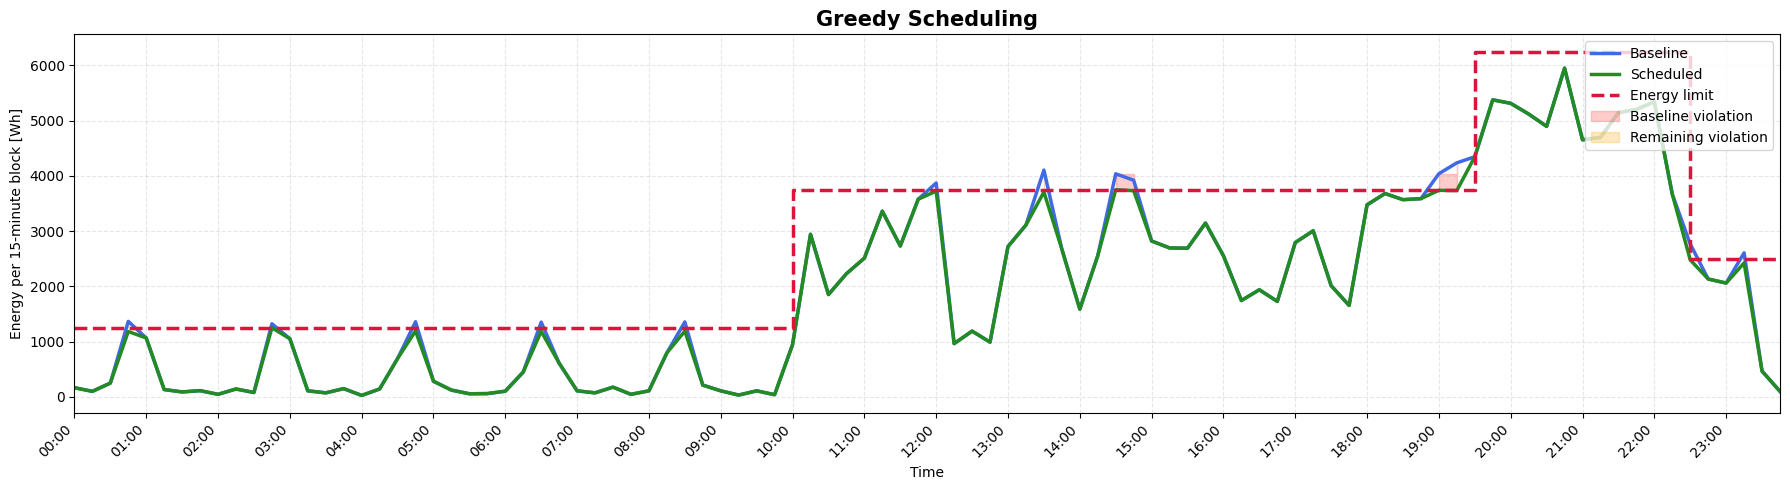

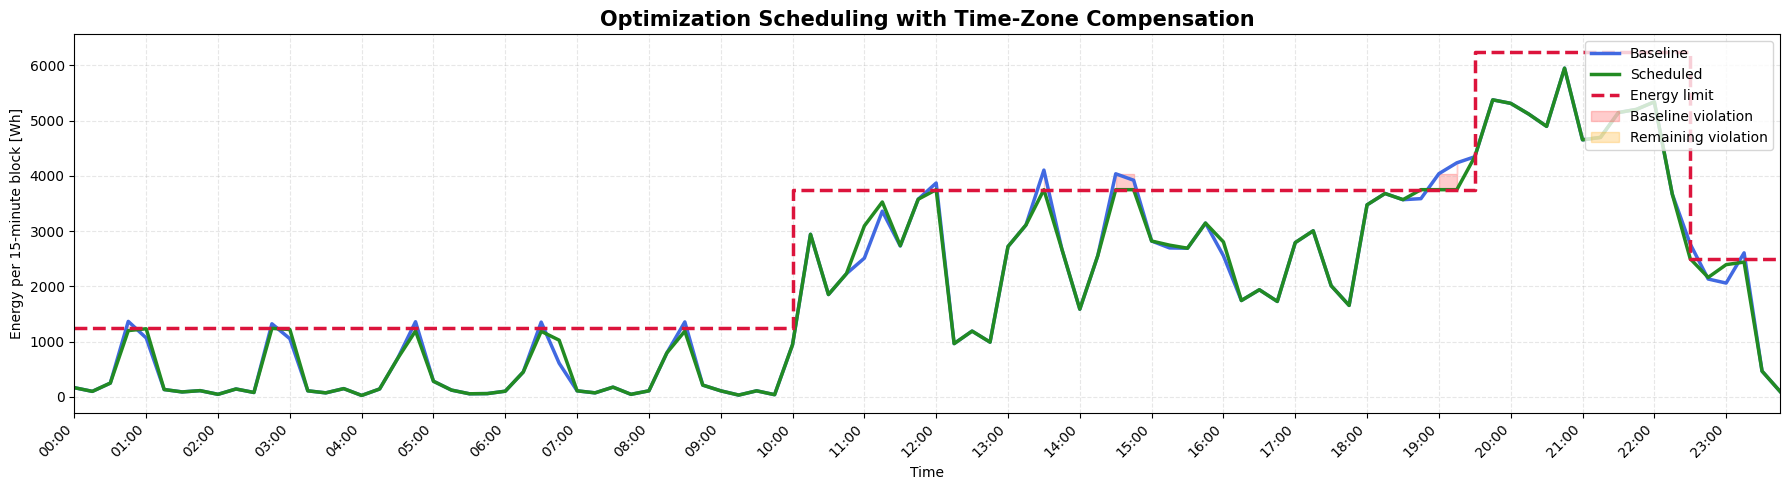

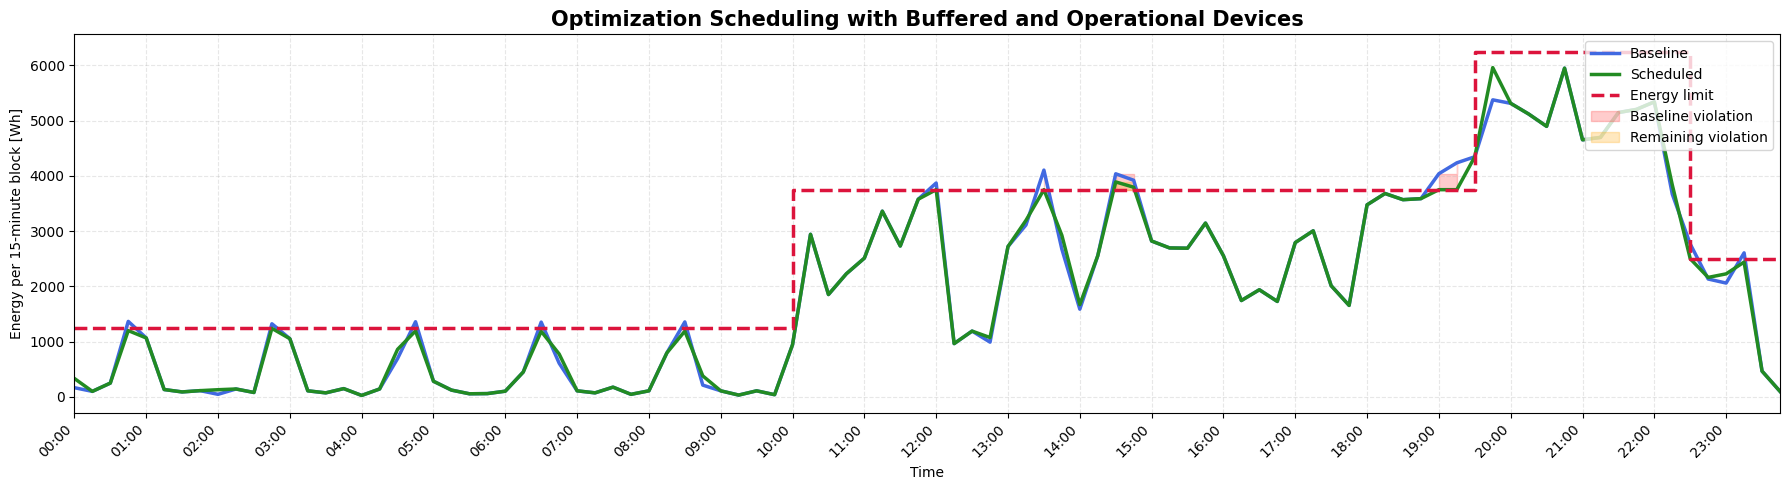

In [121]:
plot_schedule(
    greedy_summary,
    title="Greedy Scheduling"
)
plot_schedule(
    optimization_timezone_horizon,
    title="Optimization Scheduling with Time-Zone Compensation"
)
plot_schedule(
    optimization_buff_operational_comp,
    title="Optimization Scheduling with Buffered and Operational Devices"
)


#### Heatmap of devices

In [122]:
import matplotlib.pyplot as plt
import numpy as np


def plot_time_flexible_activation_heatmap(
    schedule_device,
    title="Time-flexible Scheduling Changes",
    block_size=15
):
    """
    Heatmap for time-flexible devices only.

    Value:
        Δn_on = n_on_rec - n_on_base

    Units:
        minutes ON changed within the block
    """

    df = schedule_device.copy()
    df = df[df["Type"] == 2].copy()

    if df.empty:
        print("No time-flexible devices found.")
        return

    if "n_on_base" not in df.columns:
        df["n_on_base"] = np.rint(df["DC_base"] * block_size)

    if "n_on_rec" not in df.columns:
        df["n_on_rec"] = np.rint(df["DC_rec"] * block_size)

    df["delta_n_on"] = df["n_on_rec"] - df["n_on_base"]

    heat = df.pivot_table(
        index="appliance_name",
        columns="time",
        values="delta_n_on",
        aggfunc="sum",
        fill_value=0
    )

    heat = heat.loc[np.abs(heat).sum(axis=1) > 1e-6]

    if heat.empty:
        print("No time-flexible scheduling changes.")
        return

    vmax = max(1, np.max(np.abs(heat.values)))

    fig, ax = plt.subplots(figsize=(18, max(5, len(heat) * 0.45)))

    im = ax.imshow(
        heat.values,
        aspect="auto",
        cmap="coolwarm",
        interpolation="nearest",
        vmin=-vmax,
        vmax=vmax
    )

    ax.set_yticks(np.arange(len(heat.index)))
    ax.set_yticklabels(heat.index)

    step = max(1, heat.shape[1] // 24)
    ax.set_xticks(np.arange(0, heat.shape[1], step))
    ax.set_xticklabels(heat.columns[::step], rotation=45, ha="right")

    ax.set_xlabel("Time")
    ax.set_ylabel("Time-flexible device")
    ax.set_title(title, fontsize=15, fontweight="bold")

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\Delta n_{on}$ [min/block]")

    plt.tight_layout()
    plt.show()


def plot_power_flexible_y_heatmap(
    schedule_device,
    title="Power-flexible Scheduling Changes"
):
    """
    Heatmap for power-flexible devices only.

    Value:
        ΔY = Y_rec - Y_base

    Units:
        power fraction change
    """

    df = schedule_device.copy()
    df = df[df["Type"] == 1].copy()

    if df.empty:
        print("No power-flexible devices found.")
        return

    df["delta_Y"] = df["Y_rec"] - df["Y_base"]

    heat = df.pivot_table(
        index="appliance_name",
        columns="time",
        values="delta_Y",
        aggfunc="sum",
        fill_value=0
    )

    heat = heat.loc[np.abs(heat).sum(axis=1) > 1e-6]

    if heat.empty:
        print("No power-flexible scheduling changes.")
        return

    vmax = max(0.1, np.max(np.abs(heat.values)))

    fig, ax = plt.subplots(figsize=(18, max(4, len(heat) * 0.7)))

    im = ax.imshow(
        heat.values,
        aspect="auto",
        cmap="coolwarm",
        interpolation="nearest",
        vmin=-vmax,
        vmax=vmax
    )

    ax.set_yticks(np.arange(len(heat.index)))
    ax.set_yticklabels(heat.index)

    step = max(1, heat.shape[1] // 24)
    ax.set_xticks(np.arange(0, heat.shape[1], step))
    ax.set_xticklabels(heat.columns[::step], rotation=45, ha="right")

    ax.set_xlabel("Time")
    ax.set_ylabel("Power-flexible device")
    ax.set_title(title, fontsize=15, fontweight="bold")

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(r"$\Delta Y$")

    plt.tight_layout()
    plt.show()

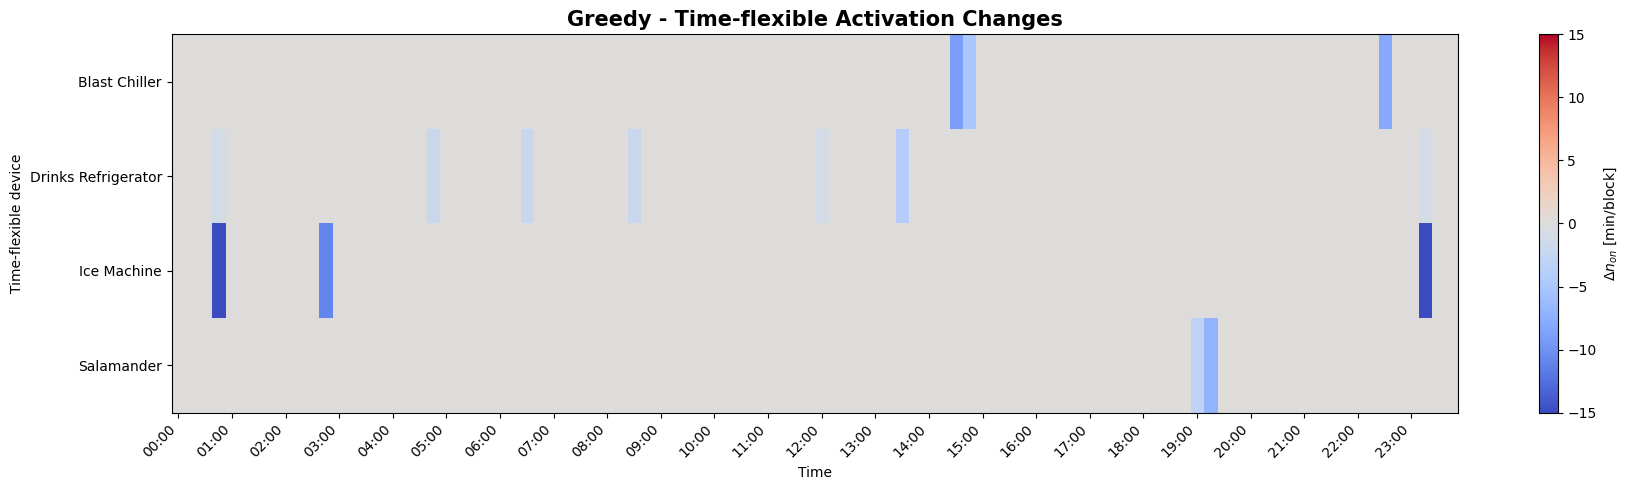

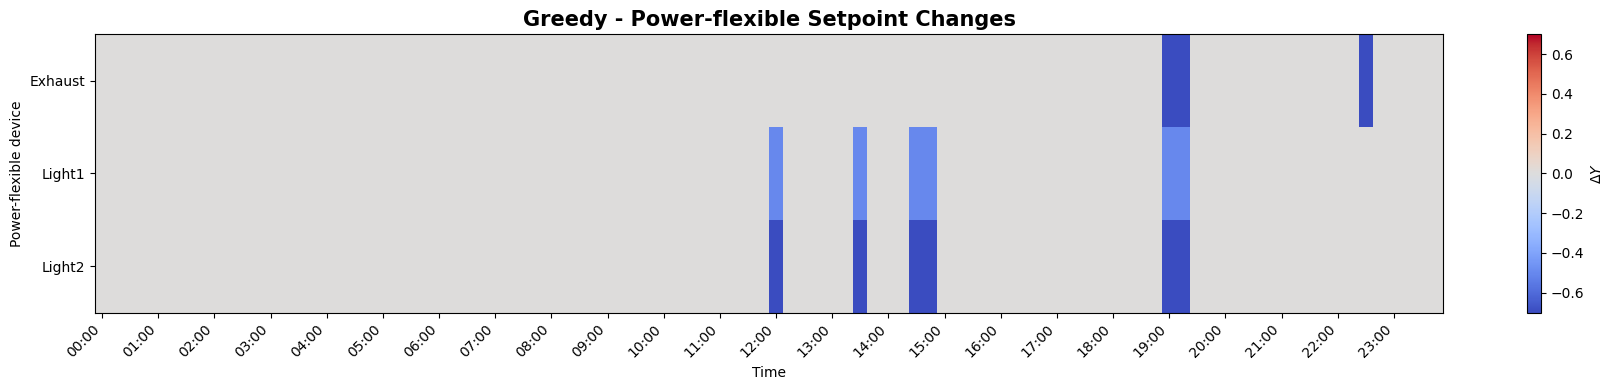

In [123]:
plot_time_flexible_activation_heatmap(
    schedule_15min_device,
    title="Greedy - Time-flexible Activation Changes",
    block_size=BLOCK_SIZE
)

plot_power_flexible_y_heatmap(
    schedule_15min_device,
    title="Greedy - Power-flexible Setpoint Changes"
)

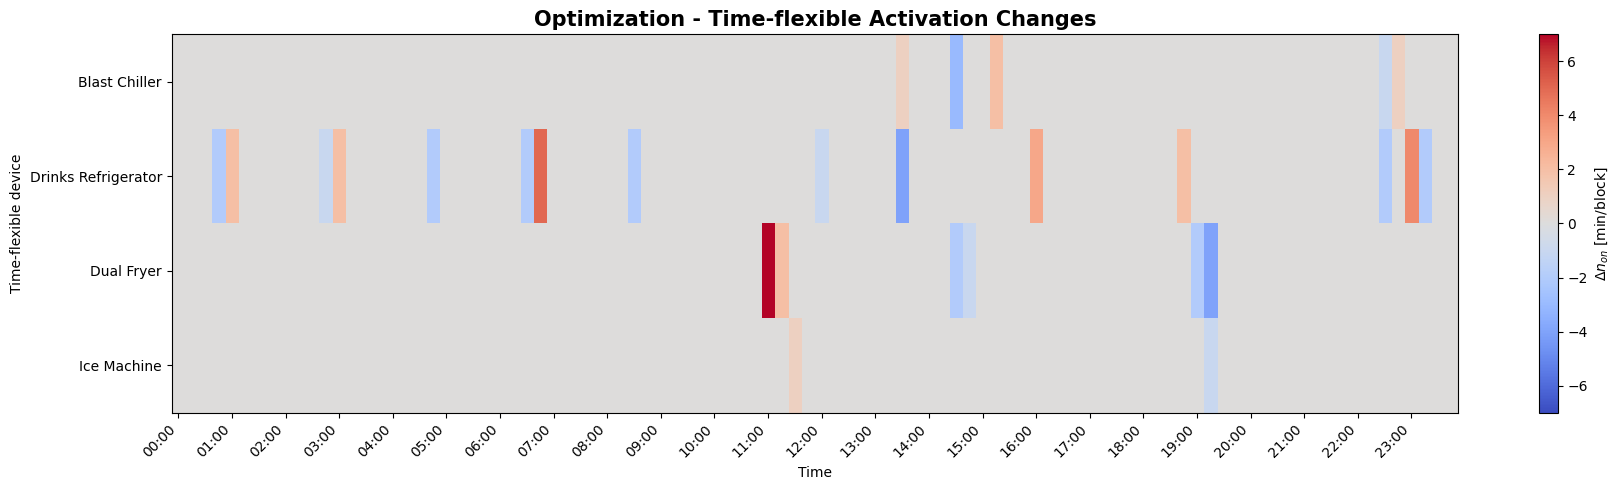

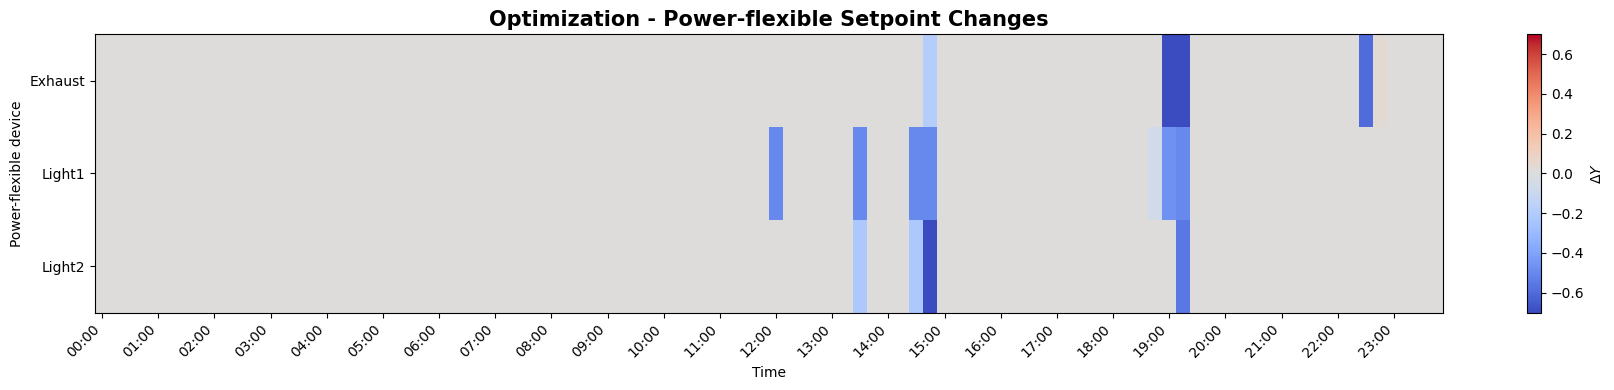

In [124]:
plot_time_flexible_activation_heatmap(
    optimization_timezone_horizon_15min_device,
    title="Optimization - Time-flexible Activation Changes",
    block_size=BLOCK_SIZE
)

plot_power_flexible_y_heatmap(
    optimization_timezone_horizon_15min_device,
    title="Optimization - Power-flexible Setpoint Changes"
)

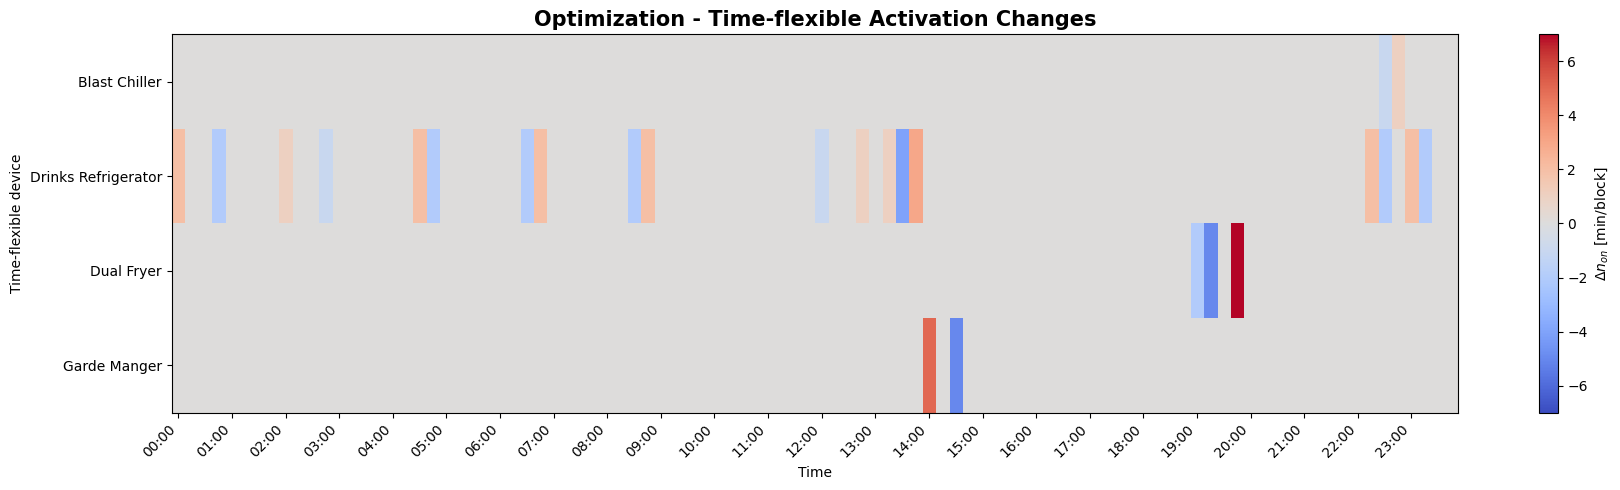

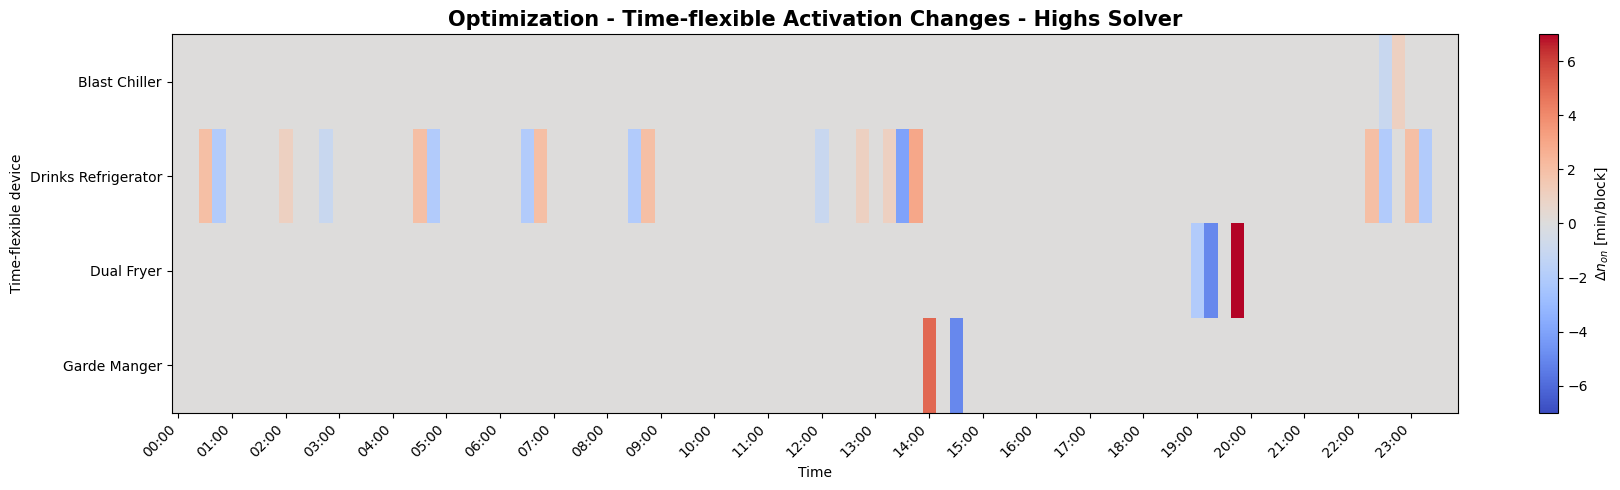

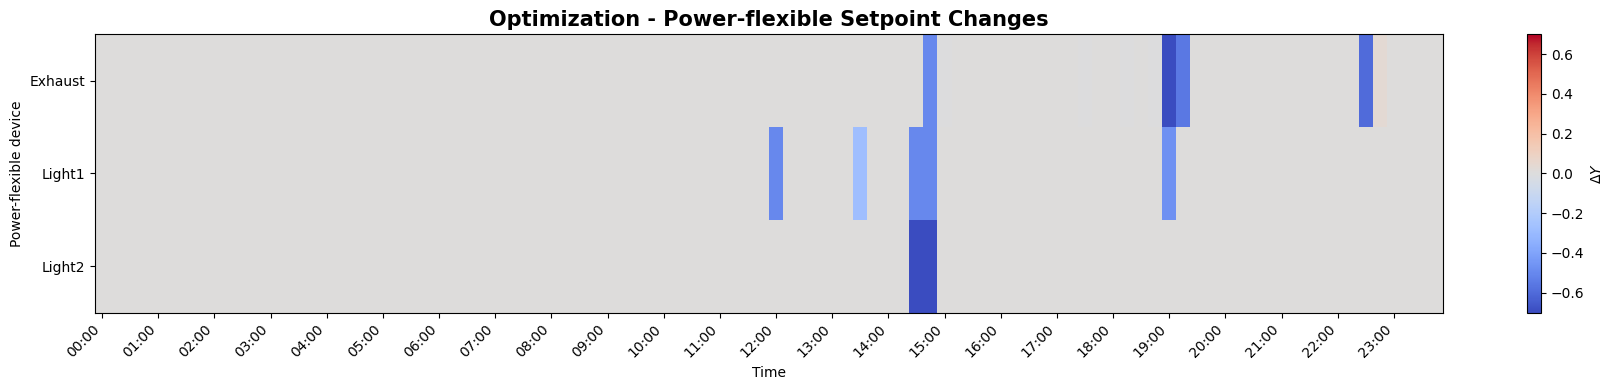

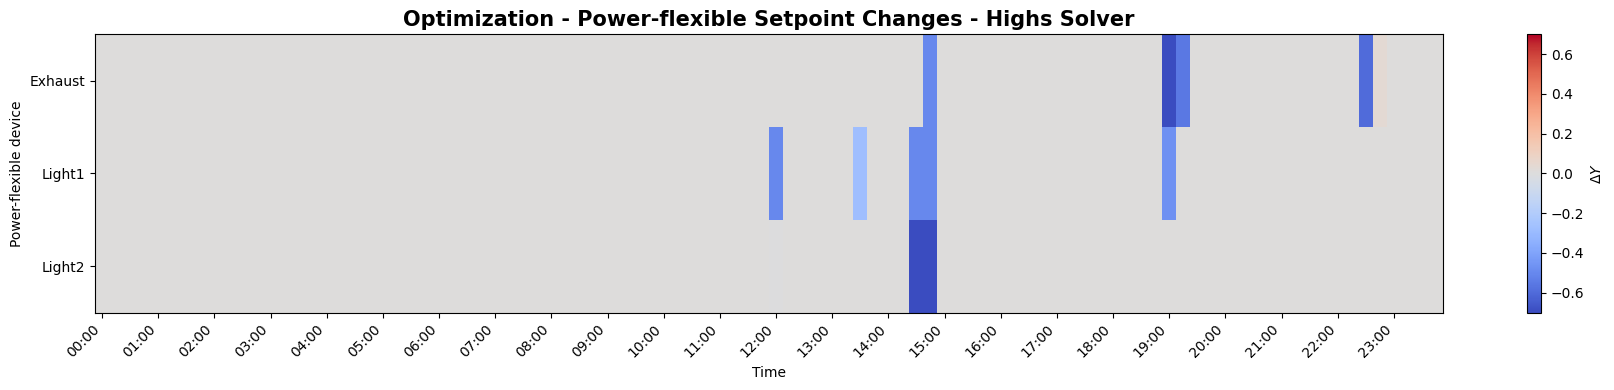

In [125]:
plot_time_flexible_activation_heatmap(
    optimization_buff_operational_comp_15min_device,
    title="Optimization - Time-flexible Activation Changes",
    block_size=BLOCK_SIZE
)
plot_time_flexible_activation_heatmap(
    optimization_buff_operational_comp_15min_device_higgs,
    title="Optimization - Time-flexible Activation Changes - Highs Solver",
    block_size=BLOCK_SIZE
)

plot_power_flexible_y_heatmap(
    optimization_buff_operational_comp_15min_device,
    title="Optimization - Power-flexible Setpoint Changes"
)
plot_power_flexible_y_heatmap(
    optimization_buff_operational_comp_15min_device_higgs,
    title="Optimization - Power-flexible Setpoint Changes - Highs Solver"
)

#### Power Limit Violations

In [126]:
def count_power_limit_violations(summary_df, tolerance=1e-6):
    """
    Counts the number of 15-minute blocks in which the reconstructed
    energy exceeds the energy limit.

    Parameters
    ----------
    summary_df : pd.DataFrame
        Must contain either:
        - 'remaining_violation_Wh'
        or
        - 'E_rec_Wh' and 'E_lim_Wh'

    tolerance : float
        Numerical tolerance in Wh.

    Returns
    -------
    dict
        Number and percentage of violated blocks.
    """

    df = summary_df.copy()

    if "remaining_violation_Wh" in df.columns:
        violation_mask = df["remaining_violation_Wh"] > tolerance

    elif {"E_rec_Wh", "E_lim_Wh"}.issubset(df.columns):
        violation_mask = (
            df["E_rec_Wh"] - df["E_lim_Wh"]
        ) > tolerance

    else:
        raise ValueError(
            "summary_df must contain 'remaining_violation_Wh' "
            "or both 'E_rec_Wh' and 'E_lim_Wh'."
        )

    n_violations = int(violation_mask.sum())
    n_blocks = len(df)

    return {
        "n_violations": n_violations,
        "n_compliant_blocks": n_blocks - n_violations,
        "n_blocks": n_blocks,
        "violation_rate_pct": 100 * n_violations / n_blocks,
        "compliance_rate_pct": 100 * (n_blocks - n_violations) / n_blocks
    }

In [127]:
power_limit_comparison = pd.DataFrame([
    {
        "Method": "Baseline",
        **count_power_limit_violations(baseline_summary)
    },
    {
        "Method": "Greedy",
        **count_power_limit_violations(greedy_summary)
    },
    {
        "Method": "Optimization/Time-Zone Compensation",
        **count_power_limit_violations(
            optimization_timezone_horizon
        )
    },
    {
        "Method": "Buffered/Operational Optimization",
        **count_power_limit_violations(
            optimization_buff_operational_comp
        )
    }
])

power_limit_comparison

,Method,n_violations,n_compliant_blocks,n_blocks,violation_rate_pct,compliance_rate_pct
0,Baseline,13,83,96,13.541667,86.458333
1,Greedy,0,96,96,0.000000,100.000000
2,Optimization/Time-Zone Compensation,0,96,96,0.000000,100.000000
3,Buffered/Operational Optimization,2,94,96,2.083333,97.916667


#### Blocos Alterados

In [128]:
def count_changed_blocks_per_device(
    df,
    dc_tolerance=1e-6,
    y_tolerance=1e-6
):
    """
    Counts how many 15-minute blocks were changed for each device.

    Type 2:
        compares DC_rec with DC_base

    Type 1:
        compares Y_rec with Y_base

    Type 0:
        assumed unchanged
    """

    data = df.copy()

    if "DC_base" not in data.columns:
        data["DC_base"] = data["Duty_Cycle"].fillna(0.0)

    if "DC_rec" not in data.columns:
        data["DC_rec"] = data["DC_base"]

    if "Y_base" not in data.columns:
        data["Y_base"] = data["Y_base"].fillna(0.0)

    if "Y_rec" not in data.columns:
        data["Y_rec"] = data["Y_base"]

    data["block_changed"] = False

    mask_t = data["Type"] == 2
    mask_p = data["Type"] == 1

    data.loc[mask_t, "block_changed"] = (
        data.loc[mask_t, "DC_rec"]
        - data.loc[mask_t, "DC_base"]
    ).abs() > dc_tolerance

    data.loc[mask_p, "block_changed"] = (
        data.loc[mask_p, "Y_rec"]
        - data.loc[mask_p, "Y_base"]
    ).abs() > y_tolerance

    group_cols = ["appliance_j"]

    if "Appliance" in data.columns:
        group_cols.append("Appliance")
    elif "appliance_name" in data.columns:
        group_cols.append("appliance_name")

    result = (
        data.groupby(group_cols, as_index=False)
        .agg(
            Type=("Type", "first"),
            changed_blocks=("block_changed", "sum"),
            total_blocks=("block", "nunique")
        )
    )

    result["changed_blocks"] = result["changed_blocks"].astype(int)

    result["changed_blocks_pct"] = (
        100
        * result["changed_blocks"]
        / result["total_blocks"]
    )
    result["device_name"] = result["appliance_j"].map(DEVICE_NAMES)

    return result.sort_values(
        "changed_blocks",
        ascending=False
    )
greedy_changed_blocks = count_changed_blocks_per_device(
    schedule_15min_device
)

timezone_changed_blocks = count_changed_blocks_per_device(
    optimization_timezone_horizon_15min_device
)

optimization_changed_blocks = count_changed_blocks_per_device(
    optimization_buff_operational_comp_15min_device
)

In [129]:
greedy_comp = greedy_changed_blocks[
    [
        "appliance_j",
        "device_name",
        "changed_blocks",
        "changed_blocks_pct"
    ]
].rename(
    columns={
        "changed_blocks": "Greedy_changed_blocks",
        "changed_blocks_pct": "Greedy_changed_pct"
    }
)

timezone_comp = timezone_changed_blocks[
    [
        "appliance_j",
        "device_name",
        "changed_blocks",
        "changed_blocks_pct"
    ]
].rename(
    columns={
        "changed_blocks": "Timezone_changed_blocks",
        "changed_blocks_pct": "Timezone_changed_pct"
    }
)

optimization_comp = optimization_changed_blocks[
    [
        "appliance_j",
        "device_name",
        "changed_blocks",
        "changed_blocks_pct"
    ]
].rename(
    columns={
        "changed_blocks": "BufferedOperational_changed_blocks",
        "changed_blocks_pct": "BufferedOperational_changed_pct"
    }
)

changed_blocks_comparison = (
    greedy_comp
    .merge(
        timezone_comp,
        on=["appliance_j", "device_name"],
        how="outer"
    )
    .merge(
        optimization_comp,
        on=["appliance_j", "device_name"],
        how="outer"
    )
    .fillna(0)
)

changed_blocks_comparison[
    "Greedy_vs_Timezone"
] = (
    changed_blocks_comparison["Greedy_changed_blocks"]
    -
    changed_blocks_comparison["Timezone_changed_blocks"]
)

changed_blocks_comparison[
    "Greedy_vs_BufferedOperational"
] = (
    changed_blocks_comparison["Greedy_changed_blocks"]
    -
    changed_blocks_comparison["BufferedOperational_changed_blocks"]
)

changed_blocks_comparison[
    "Timezone_vs_BufferedOperational"
] = (
    changed_blocks_comparison["Timezone_changed_blocks"]
    -
    changed_blocks_comparison["BufferedOperational_changed_blocks"]
)

changed_blocks_comparison = changed_blocks_comparison.sort_values(
    "Greedy_changed_blocks",
    ascending=False
)

changed_blocks_comparison

,appliance_j,device_name,Greedy_changed_blocks,Greedy_changed_pct,Timezone_changed_blocks,Timezone_changed_pct,BufferedOperational_changed_blocks,BufferedOperational_changed_pct,Greedy_vs_Timezone,Greedy_vs_BufferedOperational,Timezone_vs_BufferedOperational
0,0,Drinks Refrigerator,7,7.291667,15,15.625000,19,19.791667,-8,-12,-4
10,10,Light 1,6,6.250000,7,7.291667,5,5.208333,-1,1,2
11,11,Light 2,6,6.250000,4,4.166667,2,2.083333,2,4,2
1,1,Blast Chiller,3,3.125000,5,5.208333,2,2.083333,-2,1,3
3,3,Ice Machine,3,3.125000,2,2.083333,0,0.000000,1,3,2
12,12,Exhaust,3,3.125000,5,5.208333,5,5.208333,-2,-2,0
5,5,Salamander,2,2.083333,0,0.000000,0,0.000000,2,2,0
2,2,Garde Manger,0,0.000000,0,0.000000,2,2.083333,0,-2,-2
4,4,Dual Fryer,0,0.000000,6,6.250000,3,3.125000,-6,-3,3
6,6,Infrared Shelf,0,0.000000,0,0.000000,0,0.000000,0,0,0


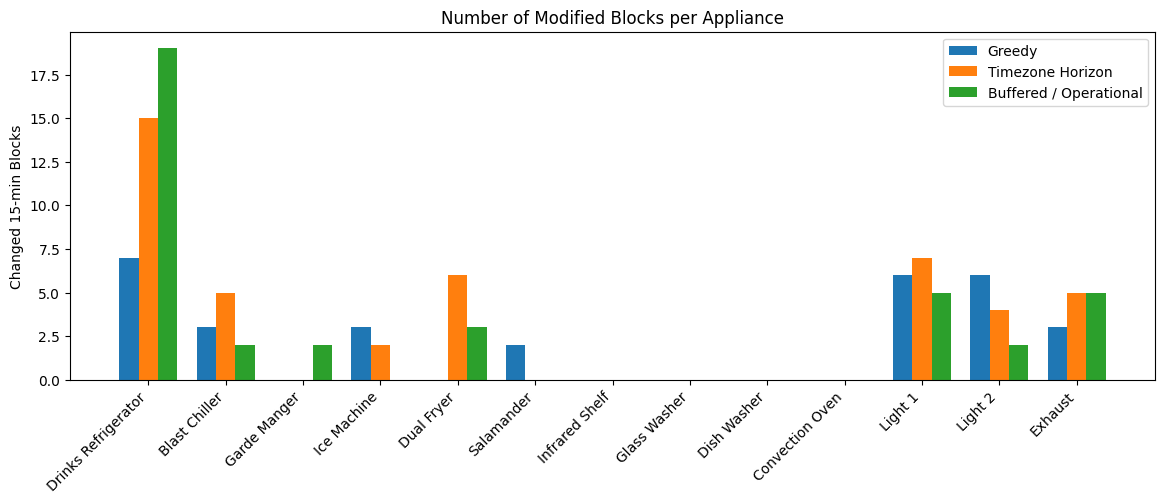

In [130]:
import matplotlib.pyplot as plt
import numpy as np

# Sort by appliance index
df = changed_blocks_comparison.sort_values("appliance_j")

x = np.arange(len(df))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

# Three bars per appliance
ax.bar(
    x - width,
    df["Greedy_changed_blocks"],
    width,
    label="Greedy"
)

ax.bar(
    x,
    df["Timezone_changed_blocks"],
    width,
    label="Timezone Horizon"
)

ax.bar(
    x + width,
    df["BufferedOperational_changed_blocks"],
    width,
    label="Buffered / Operational"
)

# Labels
ax.set_ylabel("Changed 15-min Blocks")
ax.set_title("Number of Modified Blocks per Appliance")

ax.set_xticks(x)
ax.set_xticklabels(
    df["device_name"],
    rotation=45,
    ha="right"
)

ax.legend()

# Leave enough room for the rotated labels
plt.subplots_adjust(bottom=0.30)

plt.show()

# Planeamento Flex - Devices + BESS + PV

In [ ]:
def build_day_ahead_model(
    flexibility_15min_device,
    pv_characterization,
    battery_characterization,
    battery_info,
    E_lim,
    Y_min,
    Y_max,
    BUFFERED_DEVICES,
    OPERATIONAL_DEVICES,
    block_size=15,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_grid=0.0,
    lambda_slack=1000.0,
    epsilon_P=0.1
):
    """
    Builds the day-ahead scheduling model.

    Current model includes:
        - Device characterization parameters
        - PV and BESS parameters
        - Device scheduling variables
        - Energy flow variables
        - Device flexibility constraints
        - Building energy balance
        - Grid import limit

    Not included yet:
        - PV utilization bounds
        - BESS charging/discharging bounds
        - BESS SoC dynamics
        - BESS charging/discharging exclusivity
        - Terminal SoC condition

    Energy convention
    -----------------
    All energy variables and model energy parameters are expressed in Wh.

    Device power:
        W

    PV and battery source DataFrames:
        kW and kWh, converted internally to W and Wh.
    """

    # ============================================================
    # 1. COPY INPUT DATA
    # ============================================================
    df_flex = flexibility_15min_device.copy()
    df_pv = pv_characterization.copy()
    df_bess = battery_characterization.copy()

    # ============================================================
    # 2. INPUT VALIDATION
    # ============================================================
    required_flex_columns = {
        "block",
        "appliance_j",
        "Type",
        "Power_max_W",
        "Duty_Cycle",
        "Y_base",
        "AI_T_down",
        "AI_P_down"
    }

    required_pv_columns = {
        "block",
        "PV_available_kWh"
    }

    required_bess_columns = {
        "block",
        "capacity_kWh",
        "soc_min_kWh",
        "soc_max_kWh",
        "charge_power_max_kW",
        "discharge_power_max_kW",
        "charge_energy_max_kWh",
        "discharge_energy_max_kWh",
        "eta_charge",
        "eta_discharge"
    }

    missing_flex = required_flex_columns - set(df_flex.columns)
    missing_pv = required_pv_columns - set(df_pv.columns)
    missing_bess = required_bess_columns - set(df_bess.columns)

    if missing_flex:
        raise ValueError(
            f"Missing columns in flexibility_15min_device: "
            f"{sorted(missing_flex)}"
        )

    if missing_pv:
        raise ValueError(
            f"Missing columns in pv_characterization: "
            f"{sorted(missing_pv)}"
        )

    if missing_bess:
        raise ValueError(
            f"Missing columns in battery_characterization: "
            f"{sorted(missing_bess)}"
        )

    if "soc_init_kWh" not in battery_info:
        raise ValueError(
            "battery_info must contain 'soc_init_kWh'."
        )

    # ============================================================
    # 3. SETS
    # ============================================================
    blocks = sorted(df_flex["block"].astype(int).unique())

    pv_blocks = set(df_pv["block"].astype(int))
    bess_blocks = set(df_bess["block"].astype(int))

    missing_pv_blocks = set(blocks) - pv_blocks
    missing_bess_blocks = set(blocks) - bess_blocks

    if missing_pv_blocks:
        raise ValueError(
            f"PV characterization is missing blocks: "
            f"{sorted(missing_pv_blocks)}"
        )

    if missing_bess_blocks:
        raise ValueError(
            f"Battery characterization is missing blocks: "
            f"{sorted(missing_bess_blocks)}"
        )

    J_T = sorted(
        df_flex.loc[
            df_flex["Type"] == 2,
            "appliance_j"
        ].astype(int).unique()
    )

    J_P = sorted(
        df_flex.loc[
            df_flex["Type"] == 1,
            "appliance_j"
        ].astype(int).unique()
    )

    J_NF = sorted(
        df_flex.loc[
            df_flex["Type"] == 0,
            "appliance_j"
        ].astype(int).unique()
    )

    all_devices = sorted(
        df_flex["appliance_j"].astype(int).unique()
    )

    # ============================================================
    # 4. HELPER FUNCTIONS
    # ============================================================
    def get_device_value(j, k, column, default=0.0):
        values = df_flex.loc[
            (df_flex["appliance_j"] == j)
            & (df_flex["block"] == k),
            column
        ]

        if values.empty or pd.isna(values.iloc[0]):
            return float(default)

        return float(values.iloc[0])

    def get_block_value(df, k, column):
        values = df.loc[
            df["block"] == k,
            column
        ]

        if values.empty:
            raise KeyError(
                f"No value found for block {k}, column '{column}'."
            )

        value = values.iloc[0]

        if pd.isna(value):
            raise ValueError(
                f"NaN found for block {k}, column '{column}'."
            )

        return float(value)

    def get_indexed_or_scalar_value(data, k):
        """
        Supports:
            scalar
            list
            NumPy array
            pandas Series
            dictionary indexed by block
        """
        if np.isscalar(data):
            return float(data)

        return float(data[k])

    # ============================================================
    # 5. DEVICE PARAMETERS
    # ============================================================

    # Maximum appliance power [W]
    Pmax = {
        j: float(
            df_flex.loc[
                df_flex["appliance_j"] == j,
                "Power_max_W"
            ].iloc[0]
        )
        for j in all_devices
    }

    # Baseline duty cycle for time-flexible devices [-]
    DC_base = {
        (j, k): get_device_value(
            j,
            k,
            "Duty_Cycle",
            default=0.0
        )
        for j in J_T
        for k in blocks
    }

    # Baseline number of ON minutes in each block [min]
    n_base = {
        (j, k): int(
            round(
                DC_base[j, k] * block_size
            )
        )
        for j in J_T
        for k in blocks
    }

    # Baseline power fraction for power-flexible devices [-]
    Y_base = {
        (j, k): get_device_value(
            j,
            k,
            "Y_base",
            default=0.0
        )
        for j in J_P
        for k in blocks
    }

    # Downward availability index for time flexibility [-]
    ADF_T = {
        (j, k): get_device_value(
            j,
            k,
            "AI_T_down",
            default=0.0
        )
        for j in J_T
        for k in blocks
    }

    # Downward availability index for power flexibility [-]
    ADF_P = {
        (j, k): get_device_value(
            j,
            k,
            "AI_P_down",
            default=0.0
        )
        for j in J_P
        for k in blocks
    }

    # Non-flexible appliance energy [Wh/block]
    E_NF = {}

    for k in blocks:
        E_NF[k] = sum(
            Pmax[j]
            * get_device_value(
                j,
                k,
                "Duty_Cycle",
                default=0.0
            )
            * block_size
            / 60.0
            for j in J_NF
        )

    # Grid import energy limit [Wh/block]
    E_lim_dict = {
        k: get_indexed_or_scalar_value(E_lim, k)
        for k in blocks
    }

    # ============================================================
    # 6. PV PARAMETERS
    # ============================================================

    # Available PV energy [Wh/block]
    PV_available = {
        k: 1000.0 * get_block_value(
            df_pv,
            k,
            "PV_available_kWh"
        )
        for k in blocks
    }

    # Optional information, not required by the current constraints
    PV_available_power_mean = {
        k: 1000.0 * get_block_value(
            df_pv,
            k,
            "PV_available_kW_mean"
        )
        if "PV_available_kW_mean" in df_pv.columns
        else np.nan
        for k in blocks
    }

    # ============================================================
    # 7. BATTERY PARAMETERS
    # ============================================================

    # Energy stored in the battery [Wh]
    SoC_init = (
        1000.0
        * float(battery_info["soc_init_kWh"])
    )

    SoC_min = {
        k: 1000.0 * get_block_value(
            df_bess,
            k,
            "soc_min_kWh"
        )
        for k in blocks
    }

    SoC_max = {
        k: 1000.0 * get_block_value(
            df_bess,
            k,
            "soc_max_kWh"
        )
        for k in blocks
    }

    # Maximum power [W]
    charge_power_max = {
        k: 1000.0 * get_block_value(
            df_bess,
            k,
            "charge_power_max_kW"
        )
        for k in blocks
    }

    discharge_power_max = {
        k: 1000.0 * get_block_value(
            df_bess,
            k,
            "discharge_power_max_kW"
        )
        for k in blocks
    }

    # Maximum exchanged energy per block [Wh]
    charge_energy_max = {
        k: 1000.0 * get_block_value(
            df_bess,
            k,
            "charge_energy_max_kWh"
        )
        for k in blocks
    }

    discharge_energy_max = {
        k: 1000.0 * get_block_value(
            df_bess,
            k,
            "discharge_energy_max_kWh"
        )
        for k in blocks
    }

    eta_charge = {
        k: get_block_value(
            df_bess,
            k,
            "eta_charge"
        )
        for k in blocks
    }

    eta_discharge = {
        k: get_block_value(
            df_bess,
            k,
            "eta_discharge"
        )
        for k in blocks
    }

    # The present characterization does not contain a minimum
    # charging power. It is therefore set to zero.
    charge_power_min = {
        k: 0.0
        for k in blocks
    }

    charge_energy_min = {
        k: (
            charge_power_min[k]
            * block_size
            / 60.0
        )
        for k in blocks
    }

    # ============================================================
    # 8. PYOMO MODEL
    # ============================================================
    m = pe.ConcreteModel(
        name="Day-ahead flexibility scheduling"
    )

    # ----------------------------
    # Sets
    # ----------------------------
    m.K = pe.Set(
        initialize=blocks,
        ordered=True
    )

    m.JT = pe.Set(
        initialize=J_T,
        ordered=True
    )

    m.JP = pe.Set(
        initialize=J_P,
        ordered=True
    )

    # ----------------------------
    # Pyomo parameters
    # ----------------------------
    m.Pmax = pe.Param(
        all_devices,
        initialize=Pmax,
        within=pe.NonNegativeReals
    )

    m.n_base = pe.Param(
        m.JT,
        m.K,
        initialize=n_base,
        within=pe.NonNegativeIntegers
    )

    m.DC_base = pe.Param(
        m.JT,
        m.K,
        initialize=DC_base,
        within=pe.UnitInterval
    )

    m.Y_base = pe.Param(
        m.JP,
        m.K,
        initialize=Y_base,
        within=pe.UnitInterval
    )

    m.ADF_T = pe.Param(
        m.JT,
        m.K,
        initialize=ADF_T,
        within=pe.UnitInterval
    )

    m.ADF_P = pe.Param(
        m.JP,
        m.K,
        initialize=ADF_P,
        within=pe.UnitInterval
    )

    m.E_NF = pe.Param(
        m.K,
        initialize=E_NF,
        within=pe.NonNegativeReals
    )

    m.E_lim = pe.Param(
        m.K,
        initialize=E_lim_dict,
        within=pe.NonNegativeReals
    )

    m.PV_available = pe.Param(
        m.K,
        initialize=PV_available,
        within=pe.NonNegativeReals
    )

    m.SoC_init = pe.Param(
        initialize=SoC_init,
        within=pe.NonNegativeReals
    )

    m.SoC_min = pe.Param(
        m.K,
        initialize=SoC_min,
        within=pe.NonNegativeReals
    )

    m.SoC_max = pe.Param(
        m.K,
        initialize=SoC_max,
        within=pe.NonNegativeReals
    )

    m.charge_power_max = pe.Param(
        m.K,
        initialize=charge_power_max,
        within=pe.NonNegativeReals
    )

    m.discharge_power_max = pe.Param(
        m.K,
        initialize=discharge_power_max,
        within=pe.NonNegativeReals
    )

    m.charge_energy_min = pe.Param(
        m.K,
        initialize=charge_energy_min,
        within=pe.NonNegativeReals
    )

    m.charge_energy_max = pe.Param(
        m.K,
        initialize=charge_energy_max,
        within=pe.NonNegativeReals
    )

    m.discharge_energy_max = pe.Param(
        m.K,
        initialize=discharge_energy_max,
        within=pe.NonNegativeReals
    )

    m.eta_charge = pe.Param(
        m.K,
        initialize=eta_charge,
        within=pe.PercentFraction
    )

    m.eta_discharge = pe.Param(
        m.K,
        initialize=eta_discharge,
        within=pe.PercentFraction
    )

    # ============================================================
    # 9. DECISION VARIABLES
    # ============================================================

    # Number of ON minutes for time-flexible devices [min/block]
    m.n_on = pe.Var(
        m.JT,
        m.K,
        domain=pe.NonNegativeIntegers,
        bounds=(0, block_size)
    )

    # Power fraction of power-flexible devices [-]
    m.Y_rec = pe.Var(
        m.JP,
        m.K,
        domain=pe.NonNegativeReals,
        bounds=(0.0, 1.0)
    )

    # Absolute deviation in ON minutes [min/block]
    m.dN = pe.Var(
        m.JT,
        m.K,
        domain=pe.NonNegativeReals
    )

    # Absolute deviation in power fraction [-]
    m.dY = pe.Var(
        m.JP,
        m.K,
        domain=pe.NonNegativeReals
    )

    # Battery charging energy [Wh/block]
    m.E_ch = pe.Var(
        m.K,
        domain=pe.NonNegativeReals
    )

    # Battery discharging energy [Wh/block]
    m.E_dch = pe.Var(
        m.K,
        domain=pe.NonNegativeReals
    )

    # PV energy used locally [Wh/block]
    m.E_PV = pe.Var(
        m.K,
        domain=pe.NonNegativeReals
    )

    # Grid import energy [Wh/block]
    m.E_grid = pe.Var(
        m.K,
        domain=pe.NonNegativeReals
    )

    # Grid-limit relaxation [Wh/block]
    m.E_rlx = pe.Var(
        m.K,
        domain=pe.NonNegativeReals
    )

    # Battery stored energy at the end of each block [Wh]
    m.SoC = pe.Var(
        m.K,
        domain=pe.NonNegativeReals
    )

    # Binary battery operating mode:
    # 1 = charging
    # 0 = discharging or idle
    #
    # It is declared now but will only be used when the
    # battery constraints are added.
    m.u_ch = pe.Var(
        m.K,
        domain=pe.Binary
    )

    # ============================================================
    # 10. DEVICE ENERGY EXPRESSIONS
    # ============================================================

    def time_flexible_energy_rule(m, k):
        return sum(
            m.Pmax[j]
            * m.n_on[j, k]
            / 60.0
            for j in m.JT
        )

    m.E_time = pe.Expression(
        m.K,
        rule=time_flexible_energy_rule
    )

    def power_flexible_energy_rule(m, k):
        return sum(
            m.Pmax[j]
            * m.Y_rec[j, k]
            * block_size
            / 60.0
            for j in m.JP
        )

    m.E_power = pe.Expression(
        m.K,
        rule=power_flexible_energy_rule
    )

    def total_load_energy_rule(m, k):
        return (
            m.E_time[k]
            + m.E_power[k]
            + m.E_NF[k]
        )

    m.E_load = pe.Expression(
        m.K,
        rule=total_load_energy_rule
    )

    # ============================================================
    # 11. ENERGY BALANCE
    # ============================================================

    def energy_balance_rule(m, k):
        """
        Consumption side:
            device load + battery charging

        Supply side:
            grid + PV + battery discharging
        """
        return (
            m.E_load[k]
            + m.E_ch[k]
            ==
            m.E_grid[k]
            + m.E_PV[k]
            + m.E_dch[k]
        )

    m.energy_balance = pe.Constraint(
        m.K,
        rule=energy_balance_rule
    )

    # ============================================================
    # 12. GRID IMPORT LIMIT
    # ============================================================

    def grid_import_limit_rule(m, k):
        return (
            m.E_grid[k]
            <=
            m.E_lim[k]
            + m.E_rlx[k]
        )

    m.grid_import_limit = pe.Constraint(
        m.K,
        rule=grid_import_limit_rule
    )

    # ============================================================
    # 13. TIME-FLEXIBLE DEVICE COMPENSATION
    # ============================================================

    if 60 % block_size != 0:
        raise ValueError(
            "block_size must divide 60 minutes exactly for the "
            "current fixed one-hour compensation windows."
        )

    window_size = 60 // block_size
    ordered_blocks = list(blocks)

    J_buffered = sorted(
        set(J_T).intersection(
            set(BUFFERED_DEVICES)
        )
    )

    J_operational = sorted(
        set(J_T).intersection(
            set(OPERATIONAL_DEVICES)
        )
    )

    # ------------------------------------------------------------
    # Buffered devices
    # Free redistribution inside each one-hour window
    # ------------------------------------------------------------
    for j in J_buffered:

        for start in range(
            0,
            len(ordered_blocks),
            window_size
        ):
            window_blocks = ordered_blocks[
                start:start + window_size
            ]

            if not window_blocks:
                continue

            m.add_component(
                f"buffered_conservation_j{j}_w{start}",
                pe.Constraint(
                    expr=sum(
                        m.n_on[j, k]
                        for k in window_blocks
                    )
                    ==
                    sum(
                        m.n_base[j, k]
                        for k in window_blocks
                    )
                )
            )

    # ------------------------------------------------------------
    # Operational devices
    # Postponement only inside each one-hour window
    # ------------------------------------------------------------
    for j in J_operational:

        for start in range(
            0,
            len(ordered_blocks),
            window_size
        ):
            window_blocks = ordered_blocks[
                start:start + window_size
            ]

            if not window_blocks:
                continue

            # Energy/activation conservation over the hour
            m.add_component(
                f"operational_conservation_j{j}_w{start}",
                pe.Constraint(
                    expr=sum(
                        m.n_on[j, k]
                        for k in window_blocks
                    )
                    ==
                    sum(
                        m.n_base[j, k]
                        for k in window_blocks
                    )
                )
            )

            # No anticipation:
            # cumulative reconstructed operation cannot exceed
            # cumulative baseline operation.
            for p in range(
                len(window_blocks) - 1
            ):
                prefix_blocks = window_blocks[:p + 1]

                m.add_component(
                    (
                        f"operational_no_anticipation_"
                        f"j{j}_w{start}_p{p}"
                    ),
                    pe.Constraint(
                        expr=sum(
                            m.n_on[j, k]
                            for k in prefix_blocks
                        )
                        <=
                        sum(
                            m.n_base[j, k]
                            for k in prefix_blocks
                        )
                    )
                )

    # ============================================================
    # 14. POWER-FLEXIBLE DEVICE BOUNDS
    # ============================================================

    def y_min_rule(m, j, k):
        # Device was OFF in the baseline:
        # it cannot be activated by this downward-flexibility model.
        if pe.value(m.Y_base[j, k]) <= 1e-9:
            return m.Y_rec[j, k] == 0.0

        return m.Y_rec[j, k] >= float(Y_min[j])

    m.y_min_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_min_rule
    )

    def y_max_rule(m, j, k):
        if pe.value(m.Y_base[j, k]) <= 1e-9:
            return pe.Constraint.Skip

        return m.Y_rec[j, k] <= float(Y_max[j])

    m.y_max_constraint = pe.Constraint(
        m.JP,
        m.K,
        rule=y_max_rule
    )

    # ============================================================
    # 15. ABSOLUTE DEVIATION FOR n_on
    # ============================================================

    def dN_positive_rule(m, j, k):
        return (
            m.dN[j, k]
            >=
            m.n_on[j, k]
            - m.n_base[j, k]
        )

    m.dN_positive = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_positive_rule
    )

    def dN_negative_rule(m, j, k):
        return (
            m.dN[j, k]
            >=
            m.n_base[j, k]
            - m.n_on[j, k]
        )

    m.dN_negative = pe.Constraint(
        m.JT,
        m.K,
        rule=dN_negative_rule
    )

    # ============================================================
    # 16. ABSOLUTE DEVIATION FOR Y
    # ============================================================

    def dY_positive_rule(m, j, k):
        return (
            m.dY[j, k]
            >=
            m.Y_rec[j, k]
            - m.Y_base[j, k]
        )

    m.dY_positive = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_positive_rule
    )

    def dY_negative_rule(m, j, k):
        return (
            m.dY[j, k]
            >=
            m.Y_base[j, k]
            - m.Y_rec[j, k]
        )

    m.dY_negative = pe.Constraint(
        m.JP,
        m.K,
        rule=dY_negative_rule
    )

    # ============================================================
    # 17. TEMPORARY OBJECTIVE
    # ============================================================
    #
    # This objective is structurally valid, but the model must not
    # yet be solved because PV and battery variables do not have
    # their physical constraints.
    #
    # Without those constraints, E_PV and E_dch could supply an
    # unlimited amount of energy.
    #
    m.objective = pe.Objective(
        expr=
        lambda_slack
        * sum(
            m.E_rlx[k]
            for k in m.K
        )
        +
        lambda_grid
        * sum(
            m.E_grid[k]
            for k in m.K
        )
        +
        lambda_T
        * sum(
            (1.0 - m.ADF_T[j, k])
            * m.dN[j, k]
            for j in m.JT
            for k in m.K
        )
        +
        lambda_P
        * sum(
            (
                epsilon_P
                + 1.0
                - m.ADF_P[j, k]
            )
            * m.dY[j, k]
            for j in m.JP
            for k in m.K
        ),
        sense=pe.minimize
    )

    # ============================================================
    # 18. AUXILIARY DATA
    # ============================================================
    model_data = {
        "blocks": blocks,
        "J_T": J_T,
        "J_P": J_P,
        "J_NF": J_NF,
        "J_buffered": J_buffered,
        "J_operational": J_operational,
        "Pmax_W": Pmax,
        "DC_base": DC_base,
        "n_base_min": n_base,
        "Y_base": Y_base,
        "ADF_T": ADF_T,
        "ADF_P": ADF_P,
        "E_NF_Wh": E_NF,
        "E_lim_Wh": E_lim_dict,
        "PV_available_Wh": PV_available,
        "SoC_init_Wh": SoC_init,
        "SoC_min_Wh": SoC_min,
        "SoC_max_Wh": SoC_max,
        "charge_power_max_W": charge_power_max,
        "discharge_power_max_W": discharge_power_max,
        "charge_energy_min_Wh": charge_energy_min,
        "charge_energy_max_Wh": charge_energy_max,
        "discharge_energy_max_Wh": discharge_energy_max,
        "eta_charge": eta_charge,
        "eta_discharge": eta_discharge
    }

    return m, model_data

day_ahead_model, day_ahead_data = build_day_ahead_model(
    flexibility_15min_device=flexibility_15min_device,
    pv_characterization=pv_characterization,
    battery_characterization=battery_characterization,
    battery_info=battery_info,
    E_lim=E_lim,
    Y_min=Y_min,
    Y_max=Y_max,
    BUFFERED_DEVICES=BUFFERED_DEVICES,
    OPERATIONAL_DEVICES=OPERATIONAL_DEVICES,
    block_size=BLOCK_SIZE,
    lambda_T=1.0,
    lambda_P=1.0,
    lambda_grid=0.0,
    lambda_slack=1000.0,
    epsilon_P=0.1
)

In [133]:
print(
    f"Blocks: {len(day_ahead_model.K)}"
)

print(
    f"Time-flexible devices: "
    f"{len(day_ahead_model.JT)}"
)

print(
    f"Power-flexible devices: "
    f"{len(day_ahead_model.JP)}"
)

print(
    f"Variables: "
    f"{day_ahead_model.nvariables()}"
)

print(
    f"Constraints: "
    f"{day_ahead_model.nconstraints()}")

Blocks: 96
Time-flexible devices: 7
Power-flexible devices: 3
Variables: 2592
Constraints: 3061
